<a href="https://colab.research.google.com/github/kadirilikhithalahiri/personal-finance-analyzer/blob/main/notebooks/Personal_Finance_Analyzer.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

# Install required packages
!pip install -q kagglehub pandas numpy matplotlib seaborn openpyxl scikit-learn

# Import libraries
import kagglehub
import pandas as pd
import numpy as np
import os

# Download the dataset
path = kagglehub.dataset_download("anandshaw2001/amazon-sales-dataset")

print("Path to dataset files:", path)

# Display downloaded files
print("\nFiles in dataset folder:")
print(os.listdir(path))


Using Colab cache for faster access to the 'amazon-sales-dataset' dataset.
Path to dataset files: /kaggle/input/amazon-sales-dataset

Files in dataset folder:
['Amazon 2_Raw.xlsx']


In [ ]:

import os
import pandas as pd

file_path = os.path.join(path, "Amazon 2_Raw.xlsx")

if not os.path.exists(file_path):
    raise FileNotFoundError(f"Dataset not found: {file_path}")

df = pd.read_excel(file_path)

print("First 5 rows:")
print(df.head())

print("\nDataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)


First 5 rows:
         Order ID Order Date  Ship Date                   EmailID  \
0  CA-2013-138688 2013-06-13 2013-06-17   DarrinVanHuff@gmail.com   
1  CA-2011-115812 2011-06-09 2011-06-14  BrosinaHoffman@gmail.com   
2  CA-2011-115812 2011-06-09 2011-06-14  BrosinaHoffman@gmail.com   
3  CA-2011-115812 2011-06-09 2011-06-14  BrosinaHoffman@gmail.com   
4  CA-2011-115812 2011-06-09 2011-06-14  BrosinaHoffman@gmail.com   

                              Geography     Category  \
0  United States,Los Angeles,California       Labels   
1  United States,Los Angeles,California  Furnishings   
2  United States,Los Angeles,California          Art   
3  United States,Los Angeles,California       Phones   
4  United States,Los Angeles,California      Binders   

                                        Product Name    Sales  Quantity  \
0  Self-Adhesive Address Labels for Typewriters b...   14.620         2   
1  Eldon Expressions Wood and Plastic Desk Access...   48.860         7   
2        

In [ ]:

import pandas as pd
import os

excel_file = os.path.join(path, "Amazon 2_Raw.xlsx")

if not os.path.exists(excel_file):
    raise FileNotFoundError(f"Excel file not found: {excel_file}")

df = pd.read_excel(excel_file)

print("Dataset shape:", df.shape)
print("\nFirst 5 rows:")
display(df.head())


Dataset shape: (3203, 10)

First 5 rows:


,Order ID,Order Date,Ship Date,EmailID,Geography,Category,Product Name,Sales,Quantity,Profit
0,CA-2013-138688,2013-06-13,2013-06-17,DarrinVanHuff@gmail.com,"United States,Los Angeles,California",Labels,Self-Adhesive Address Labels for Typewriters b...,14.620,2,6.8714
1,CA-2011-115812,2011-06-09,2011-06-14,BrosinaHoffman@gmail.com,"United States,Los Angeles,California",Furnishings,Eldon Expressions Wood and Plastic Desk Access...,48.860,7,14.1694
2,CA-2011-115812,2011-06-09,2011-06-14,BrosinaHoffman@gmail.com,"United States,Los Angeles,California",Art,Newell 322,7.280,4,1.9656
3,CA-2011-115812,2011-06-09,2011-06-14,BrosinaHoffman@gmail.com,"United States,Los Angeles,California",Phones,Mitel 5320 IP Phone VoIP phone,907.152,4,90.7152
4,CA-2011-115812,2011-06-09,2011-06-14,BrosinaHoffman@gmail.com,"United States,Los Angeles,California",Binders,DXL Angle-View Binders with Locking Rings by S...,18.504,3,5.7825


In [ ]:

# Clean column names
expected_columns = [
    "Order_ID",
    "Order_Date",
    "Ship_Date",
    "Email_ID",
    "Geography",
    "Category",
    "Product_Name",
    "Sales",
    "Quantity",
    "Profit"
]

if len(df.columns) != len(expected_columns):
    raise ValueError("Unexpected number of columns in the dataset.")

df.columns = expected_columns

# Convert date columns
df["Order_Date"] = pd.to_datetime(df["Order_Date"], errors="coerce")
df["Ship_Date"] = pd.to_datetime(df["Ship_Date"], errors="coerce")

# Convert numerical columns
df["Sales"] = pd.to_numeric(df["Sales"], errors="coerce")
df["Quantity"] = pd.to_numeric(df["Quantity"], errors="coerce")
df["Profit"] = pd.to_numeric(df["Profit"], errors="coerce")

# Display data quality information
print("Columns:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

print("\nTotal missing values:", df.isnull().sum().sum())


Columns:
['Order_ID', 'Order_Date', 'Ship_Date', 'Email_ID', 'Geography', 'Category', 'Product_Name', 'Sales', 'Quantity', 'Profit']

Data types:
Order_ID                object
Order_Date      datetime64[ns]
Ship_Date       datetime64[ns]
Email_ID                object
Geography               object
Category                object
Product_Name            object
Sales                  float64
Quantity                 int64
Profit                 float64
dtype: object

Missing values:
Order_ID        0
Order_Date      0
Ship_Date       0
Email_ID        0
Geography       0
Category        0
Product_Name    0
Sales           0
Quantity        0
Profit          0
dtype: int64

Total missing values: 0


In [ ]:

# Check duplicate records
print("Duplicate rows:", df.duplicated().sum())

# Check invalid numerical values
print("\nNegative Sales:", (df["Sales"] < 0).sum())
print("Negative Quantity:", (df["Quantity"] < 0).sum())
print("Missing Sales:", df["Sales"].isna().sum())
print("Missing Quantity:", df["Quantity"].isna().sum())
print("Missing Profit:", df["Profit"].isna().sum())

# Check date consistency
print("\nOrder Date range:")
print(df["Order_Date"].min(), "to", df["Order_Date"].max())

print("\nMissing Order Dates:", df["Order_Date"].isna().sum())
print("Missing Ship Dates:", df["Ship_Date"].isna().sum())

print(
    "Ship Date before Order Date:",
    (df["Ship_Date"] < df["Order_Date"]).sum()
)


Duplicate rows: 0

Negative Sales: 0
Negative Quantity: 0
Missing Sales: 0
Missing Quantity: 0
Missing Profit: 0

Order Date range:
2011-01-07 00:00:00 to 2014-12-31 00:00:00

Missing Order Dates: 0
Missing Ship Dates: 0
Ship Date before Order Date: 0


In [ ]:

# Create monthly time-series data
monthly_df = (
    df.dropna(subset=["Order_Date"])
      .set_index("Order_Date")
      .resample("MS")
      .agg({
          "Sales": "sum",
          "Profit": "sum",
          "Quantity": "sum"
      })
      .fillna(0)
      .reset_index()
)

# Add time-based features
monthly_df["Month"] = monthly_df["Order_Date"].dt.month
monthly_df["Quarter"] = monthly_df["Order_Date"].dt.quarter
monthly_df["Year"] = monthly_df["Order_Date"].dt.year

print("Monthly dataset shape:", monthly_df.shape)

print("\nFirst 10 rows:")
display(monthly_df.head(10))

print("\nLast 10 rows:")
display(monthly_df.tail(10))

print("\nMissing values:")
print(monthly_df.isnull().sum())

print("\nContinuous monthly dates:", monthly_df["Order_Date"].is_monotonic_increasing)


Monthly dataset shape: (48, 7)

First 10 rows:


,Order_Date,Sales,Profit,Quantity,Month,Quarter,Year
0,2011-01-01,2648.057,20.9733,62,1,1,2011
1,2011-02-01,1348.622,228.8282,49,2,1,2011
2,2011-03-01,11008.898,1534.2273,150,3,1,2011
3,2011-04-01,9343.487,1629.4545,179,4,2,2011
4,2011-05-01,6570.438,873.5640,141,5,2,2011
5,2011-06-01,9629.422,1771.8152,136,6,2,2011
6,2011-07-01,21808.553,1946.6828,260,7,3,2011
7,2011-08-01,13248.231,2560.9044,246,8,3,2011
8,2011-09-01,14900.537,3075.5227,274,9,3,2011
9,2011-10-01,8728.758,1391.2655,233,10,4,2011



Last 10 rows:


,Order_Date,Sales,Profit,Quantity,Month,Quarter,Year
38,2014-03-01,28994.3980,9107.0263,335,3,1,2014
39,2014-04-01,13196.9530,-1867.7502,220,4,2,2014
40,2014-05-01,15901.6460,2779.0547,321,5,2,2014
41,2014-06-01,15203.0785,2648.3827,290,6,2,2014
42,2014-07-01,21390.7600,4333.1607,259,7,3,2014
43,2014-08-01,24196.7580,6028.0626,322,8,3,2014
44,2014-09-01,29198.1230,4891.7154,570,9,3,2014
45,2014-10-01,21556.0060,3420.1665,395,10,4,2014
46,2014-11-01,28915.9570,3433.6926,553,11,4,2014
47,2014-12-01,29677.9250,4178.8820,634,12,4,2014



Missing values:
Order_Date    0
Sales         0
Profit        0
Quantity      0
Month         0
Quarter       0
Year          0
dtype: int64

Continuous monthly dates: True


In [ ]:

# Prepare monthly data for TFT

tft_df = monthly_df.copy()

# Ensure every calendar month is present
tft_df = (
    tft_df.set_index("Order_Date")
          .asfreq("MS")
          .reset_index()
)

# Fill months with no recorded sales
for col in ["Sales", "Profit", "Quantity"]:
    tft_df[col] = tft_df[col].fillna(0)

# Recreate time-based features
tft_df["Month"] = tft_df["Order_Date"].dt.month
tft_df["Quarter"] = tft_df["Order_Date"].dt.quarter
tft_df["Year"] = tft_df["Order_Date"].dt.year

# Create sequential time index
tft_df["time_idx"] = range(len(tft_df))

# Create series identifier
tft_df["series"] = "Amazon"

# Define prediction target
tft_df["target"] = tft_df["Sales"]

# Display prepared dataset
print("TFT dataset shape:", tft_df.shape)

display(tft_df.head())

print("\nColumns:")
print(tft_df.columns.tolist())

print("\nMissing values:")
print(tft_df.isnull().sum())

print("\nMonthly dates are continuous:",
      tft_df["Order_Date"].diff().dropna().eq(pd.Timedelta(days=0)).all()
      if len(tft_df) < 2 else
      (tft_df["Order_Date"].dt.to_period("M").diff().dropna().apply(lambda x: x.n) == 1).all())


TFT dataset shape: (48, 10)


,Order_Date,Sales,Profit,Quantity,Month,Quarter,Year,time_idx,series,target
0,2011-01-01,2648.057,20.9733,62,1,1,2011,0,Amazon,2648.057
1,2011-02-01,1348.622,228.8282,49,2,1,2011,1,Amazon,1348.622
2,2011-03-01,11008.898,1534.2273,150,3,1,2011,2,Amazon,11008.898
3,2011-04-01,9343.487,1629.4545,179,4,2,2011,3,Amazon,9343.487
4,2011-05-01,6570.438,873.5640,141,5,2,2011,4,Amazon,6570.438



Columns:
['Order_Date', 'Sales', 'Profit', 'Quantity', 'Month', 'Quarter', 'Year', 'time_idx', 'series', 'target']

Missing values:
Order_Date    0
Sales         0
Profit        0
Quantity      0
Month         0
Quarter       0
Year          0
time_idx      0
series        0
target        0
dtype: int64

Monthly dates are continuous: True


In [ ]:

# Install libraries required for Temporal Fusion Transformer
%pip install -q torch pytorch-forecasting lightning

# Import libraries
import torch
import lightning.pytorch as pl
import pytorch_forecasting

print("PyTorch version:", torch.__version__)
print("Lightning version:", pl.__version__)
print("PyTorch Forecasting version:", pytorch_forecasting.__version__)
print("GPU available:", torch.cuda.is_available())


PyTorch version: 2.11.0+cpu
Lightning version: 2.6.6
PyTorch Forecasting version: 1.8.0
GPU available: False


In [ ]:

from pytorch_forecasting import TimeSeriesDataSet

# Define the input and prediction lengths
max_encoder_length = 12
max_prediction_length = 3

# Reserve the last 12 months for validation
last_time_idx = int(tft_df["time_idx"].max())
training_cutoff = last_time_idx - 12

# Create training dataset using data before the validation period
training_data = tft_df[tft_df["time_idx"] <= training_cutoff].copy()

training = TimeSeriesDataSet(
    training_data,
    time_idx="time_idx",
    target="target",
    group_ids=["series"],

    min_encoder_length=max_encoder_length,
    max_encoder_length=max_encoder_length,
    min_prediction_length=max_prediction_length,
    max_prediction_length=max_prediction_length,

    static_categoricals=["series"],

    time_varying_known_reals=[
        "time_idx",
        "Month",
        "Quarter",
        "Year"
    ],

    time_varying_unknown_reals=[
        "target",
        "Profit",
        "Quantity"
    ],

    allow_missing_timesteps=False
)

print("Total monthly observations:", len(tft_df))
print("Training observations:", len(training_data))
print("Training cutoff:", training_cutoff)
print("Validation starts at time_idx:", training_cutoff + 1)
print("Encoder length:", max_encoder_length)
print("Prediction length:", max_prediction_length)
print("Training samples:", len(training))


Total monthly observations: 48
Training observations: 36
Training cutoff: 35
Validation starts at time_idx: 36
Encoder length: 12
Prediction length: 3
Training samples: 22


In [ ]:

# Create validation dataset from the training dataset structure
validation_data = tft_df[
    tft_df["time_idx"] > training_cutoff
].copy()

# Include historical encoder context for validation
validation_context = tft_df[
    tft_df["time_idx"] >= training_cutoff - max_encoder_length + 1
].copy()

validation = TimeSeriesDataSet.from_dataset(
    training,
    validation_context,
    predict=False,
    stop_randomization=True
)

# Create DataLoaders
batch_size = 8

train_dataloader = training.to_dataloader(
    train=True,
    batch_size=batch_size,
    num_workers=0
)

val_dataloader = validation.to_dataloader(
    train=False,
    batch_size=batch_size,
    num_workers=0
)

print("Training samples:", len(training))
print("Validation dataset samples:", len(validation))
print("Training batches:", len(train_dataloader))
print("Validation batches:", len(val_dataloader))
print("Reserved validation months:", len(validation_data))


Training samples: 22
Validation dataset samples: 10
Training batches: 2
Validation batches: 2
Reserved validation months: 12


In [ ]:

from pytorch_forecasting import TemporalFusionTransformer
from pytorch_forecasting.metrics import QuantileLoss

# Create a small Temporal Fusion Transformer model
tft = TemporalFusionTransformer.from_dataset(
    training,
    learning_rate=0.03,
    hidden_size=8,
    attention_head_size=2,
    dropout=0.1,
    hidden_continuous_size=4,
    loss=QuantileLoss(),
    output_size=7,
    reduce_on_plateau_patience=3
)

print(tft)


TemporalFusionTransformer(
  	"attention_head_size":               2
  	"categorical_groups":                {}
  	"causal_attention":                  True
  	"dataset_parameters":                {'time_idx': 'time_idx', 'target': 'target', 'group_ids': ['series'], 'weight': None, 'max_encoder_length': 12, 'min_encoder_length': 12, 'min_prediction_idx': 0, 'min_prediction_length': 3, 'max_prediction_length': 3, 'static_categoricals': ['series'], 'static_reals': None, 'time_varying_known_categoricals': None, 'time_varying_known_reals': ['time_idx', 'Month', 'Quarter', 'Year'], 'time_varying_unknown_categoricals': None, 'time_varying_unknown_reals': ['target', 'Profit', 'Quantity'], 'variable_groups': None, 'constant_fill_strategy': None, 'allow_missing_timesteps': False, 'lags': None, 'add_relative_time_idx': False, 'add_target_scales': False, 'add_encoder_length': False, 'target_normalizer': GroupNormalizer(
  		method='standard',
  		groups=None,
  		center=True,
  		scale_by_group=F

/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/parsing.py:213: Attribute 'loss' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['loss'])`.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/parsing.py:213: Attribute 'logging_metrics' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['logging_metrics'])`.


In [ ]:

from lightning.pytorch import Trainer
from lightning.pytorch.callbacks import EarlyStopping

# Stop training if validation loss does not improve
early_stop_callback = EarlyStopping(
    monitor="val_loss",
    min_delta=0.001,
    patience=5,
    mode="min"
)

# Configure the trainer
trainer = Trainer(
    max_epochs=30,
    accelerator="cpu",
    devices=1,
    gradient_clip_val=0.1,
    enable_model_summary=False,
    logger=False,
    callbacks=[early_stop_callback]
)

# Train the TFT model
trainer.fit(
    tft,
    train_dataloaders=train_dataloader,
    val_dataloaders=val_dataloader
)


INFO: GPU available: False, used: False
INFO:lightning.pytorch.utilities.rank_zero:GPU available: False, used: False
INFO: TPU available: False, using: 0 TPU cores
INFO:lightning.pytorch.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO: 💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO:lightning.pytorch.utilities.rank_zero:💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO: 💡 Tip: For seamless cloud uploads and versioning, try installing [litmodels](https://pypi.org/project/litmodels/) to enable LitModelCheckpoint, which syncs automatically with the Lightning model registry.
INFO:lightning.pytorch.utilities

Output()

/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)`
is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.

In [ ]:

import torch

# Generate predictions on the validation set
predictions = tft.predict(
    val_dataloader,
    return_y=True,
    trainer_kwargs={"accelerator": "cpu", "devices": 1}
)

# Extract predicted and actual values
predicted_values = predictions.output
actual_values = predictions.y

# Handle quantile predictions by selecting the median forecast
if predicted_values.ndim == 3:
    predicted_values = predicted_values[..., predicted_values.shape[-1] // 2]

# Extract actual target values if returned as a tuple
if isinstance(actual_values, (tuple, list)):
    actual_values = actual_values[0]

# Convert tensors to NumPy arrays
if isinstance(predicted_values, torch.Tensor):
    predicted_values = predicted_values.detach().cpu().numpy()

if isinstance(actual_values, torch.Tensor):
    actual_values = actual_values.detach().cpu().numpy()

print("Predictions shape:", predicted_values.shape)
print("Actual values shape:", actual_values.shape)

print("\nPredicted values:")
print(predicted_values)

print("\nActual values:")
print(actual_values)


INFO: GPU available: False, used: False
INFO:lightning.pytorch.utilities.rank_zero:GPU available: False, used: False
INFO: TPU available: False, using: 0 TPU cores
INFO:lightning.pytorch.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO: 💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO:lightning.pytorch.utilities.rank_zero:💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO: 💡 Tip: For seamless cloud uploads and versioning, try installing [litmodels](https://pypi.org/project/litmodels/) to enable LitModelCheckpoint, which syncs automatically with the Lightning model registry.
INFO:lightning.pytorch.utilities

Predictions shape: (10, 3)
Actual values shape: (10, 3)

Predicted values:
[[11380.29   11497.785  11663.141 ]
 [11539.296  11670.928  12158.94  ]
 [11708.472  12165.906  12373.713 ]
 [12204.373  12373.8125 13301.722 ]
 [12402.977  13296.901  15600.713 ]
 [13321.264  15600.64   16679.455 ]
 [15615.29   16680.879  17242.59  ]
 [16693.367  17248.828  18034.502 ]
 [17278.154  18044.809  18300.564 ]
 [18087.43   18312.066  18506.895 ]]

Actual values:
[[12586.004  9814.917 28994.398]
 [ 9814.917 28994.398 13196.953]
 [28994.398 13196.953 15901.646]
 [13196.953 15901.646 15203.078]
 [15901.646 15203.078 21390.76 ]
 [15203.078 21390.76  24196.758]
 [21390.76  24196.758 29198.123]
 [24196.758 29198.123 21556.006]
 [29198.123 21556.006 28915.957]
 [21556.006 28915.957 29677.926]]


In [ ]:

import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Extract median predictions and actual values
pred = predictions.output.detach().cpu().numpy()

if pred.ndim == 3:
    pred = pred[..., pred.shape[-1] // 2]

pred = pred.reshape(-1)

actual_data = predictions.y
if isinstance(actual_data, (tuple, list)):
    actual_data = actual_data[0]

actual = actual_data.detach().cpu().numpy().reshape(-1)

# Ensure predictions and actual values have matching lengths
if len(pred) != len(actual):
    raise ValueError(
        f"Length mismatch: {len(pred)} predictions and {len(actual)} actual values."
    )

# Calculate evaluation metrics
mae = mean_absolute_error(actual, pred)
rmse = np.sqrt(mean_squared_error(actual, pred))

# MAPE is undefined when actual values are zero
nonzero_mask = actual != 0
if nonzero_mask.any():
    mape = np.mean(
        np.abs((actual[nonzero_mask] - pred[nonzero_mask]) /
               actual[nonzero_mask])
    ) * 100
else:
    mape = np.nan

print("TFT Model Evaluation")
print("--------------------")
print(f"MAE  : {mae:.2f}")
print(f"RMSE : {rmse:.2f}")
print(f"MAPE : {mape:.2f}%" if not np.isnan(mape)
      else "MAPE : Undefined (all actual values are zero)")
print("Evaluated values:", len(actual))


TFT Model Evaluation
--------------------
MAE  : 6482.25
RMSE : 8249.81
MAPE : 26.90%
Evaluated values: 30


In [ ]:

# Overall Sales and Profit Analysis

total_sales = df["Sales"].sum()
average_sales = df["Sales"].mean()

total_profit = df["Profit"].sum()
average_profit = df["Profit"].mean()

# Calculate profit margin safely
profit_margin = (
    (total_profit / total_sales) * 100
    if total_sales != 0 else np.nan
)

print("Amazon Sales & Profit Analysis")
print("--------------------------------")
print(f"Total Sales     : {total_sales:,.2f}")
print(f"Average Sale    : {average_sales:,.2f}")
print(f"Total Profit    : {total_profit:,.2f}")
print(f"Average Profit  : {average_profit:,.2f}")

if not np.isnan(profit_margin):
    print(f"Profit Margin   : {profit_margin:.2f}%")
else:
    print("Profit Margin   : Undefined (total sales is zero)")


Amazon Sales & Profit Analysis
--------------------------------
Total Sales     : 725,457.82
Average Sale    : 226.49
Total Profit    : 108,418.45
Average Profit  : 33.85
Profit Margin   : 14.94%


In [ ]:

# Sales and Profit by Category

category_analysis = (
    df.groupby("Category")
      .agg(
          Total_Sales=("Sales", "sum"),
          Total_Profit=("Profit", "sum"),
          Total_Quantity=("Quantity", "sum")
      )
      .sort_values("Total_Sales", ascending=False)
      .reset_index()
)

# Calculate profit margin safely
category_analysis["Profit_Margin"] = np.where(
    category_analysis["Total_Sales"] != 0,
    (category_analysis["Total_Profit"] /
     category_analysis["Total_Sales"]) * 100,
    np.nan
)

print("Sales and Profit Analysis by Category")
display(category_analysis.round(2))


Sales and Profit Analysis by Category


,Category,Total_Sales,Total_Profit,Total_Quantity,Profit_Margin
0,Chairs,101781.33,4027.58,734,3.96
1,Phones,98684.35,9110.74,1066,9.23
2,Tables,84754.56,1482.61,481,1.75
3,Storage,70532.85,8645.32,1039,12.26
4,Accessories,61114.12,16484.60,1032,26.97
5,Binders,55961.11,16096.80,1868,28.76
6,Copiers,49749.24,19327.24,88,38.85
7,Machines,42444.12,-618.93,147,-1.46
8,Bookcases,36004.12,-1646.51,306,-4.57
9,Appliances,30236.34,8261.27,492,27.32


In [ ]:

# Sales and Profit by Geography

geography_analysis = (
    df.groupby("Geography")
      .agg(
          Total_Sales=("Sales", "sum"),
          Total_Profit=("Profit", "sum"),
          Total_Quantity=("Quantity", "sum")
      )
      .sort_values("Total_Sales", ascending=False)
      .reset_index()
)

# Calculate profit margin safely
geography_analysis["Profit_Margin"] = np.where(
    geography_analysis["Total_Sales"] != 0,
    (geography_analysis["Total_Profit"] /
     geography_analysis["Total_Sales"]) * 100,
    np.nan
)

print("Sales and Profit Analysis by Geography")
display(geography_analysis.round(2))


Sales and Profit Analysis by Geography


,Geography,Total_Sales,Total_Profit,Total_Quantity,Profit_Margin
0,"United States,Los Angeles,California",175851.34,30440.76,2877,17.31
1,"United States,Seattle,Washington",119540.74,29156.10,1590,24.39
2,"United States,San Francisco,California",112669.09,17507.39,1935,15.54
3,"United States,San Diego,California",47521.03,6377.20,670,13.42
4,"United States,Denver,Colorado",12198.79,-244.92,164,-2.01
...,...,...,...,...,...
165,"United States,Billings,Montana",8.29,2.69,2,32.50
166,"United States,Layton,Utah",4.96,2.33,4,47.00
167,"United States,Auburn,Washington",4.18,1.50,1,36.00
168,"United States,Everett,Washington",3.86,1.40,1,36.25


In [ ]:

# Top 10 Geographies by Sales

top_10_geography = (
    geography_analysis
    .nlargest(10, "Total_Sales")
    .copy()
)

print("Top 10 Geographies by Sales")
display(top_10_geography.round(2))


Top 10 Geographies by Sales


,Geography,Total_Sales,Total_Profit,Total_Quantity,Profit_Margin
0,"United States,Los Angeles,California",175851.34,30440.76,2877,17.31
1,"United States,Seattle,Washington",119540.74,29156.10,1590,24.39
2,"United States,San Francisco,California",112669.09,17507.39,1935,15.54
3,"United States,San Diego,California",47521.03,6377.20,670,13.42
4,"United States,Denver,Colorado",12198.79,-244.92,164,-2.01
5,"United States,Phoenix,Arizona",11000.26,-2790.88,224,-25.37
6,"United States,North Las Vegas,Nevada",9801.00,2247.69,58,22.93
7,"United States,Anaheim,California",7986.87,1234.00,112,15.45
8,"United States,Fresno,California",7888.53,948.27,106,12.02
9,"United States,Sacramento,California",7311.28,2069.69,36,28.31


In [ ]:

# Top 10 Products by Sales

product_analysis = (
    df.groupby("Product_Name")
      .agg(
          Total_Sales=("Sales", "sum"),
          Total_Profit=("Profit", "sum"),
          Total_Quantity=("Quantity", "sum")
      )
      .sort_values("Total_Sales", ascending=False)
      .reset_index()
)

# Calculate profit margin safely
product_analysis["Profit_Margin"] = np.where(
    product_analysis["Total_Sales"] != 0,
    (product_analysis["Total_Profit"] /
     product_analysis["Total_Sales"]) * 100,
    np.nan
)

# Select the top 10 products
top_10_products = (
    product_analysis
    .nlargest(10, "Total_Sales")
    .copy()
)

print("Top 10 Products by Sales")
display(top_10_products.round(2))


Top 10 Products by Sales


,Product_Name,Total_Sales,Total_Profit,Total_Quantity,Profit_Margin
0,Canon imageCLASS 2200 Advanced Copier,13999.96,6719.98,4,48.00
1,High Speed Automatic Electric Letter Opener,13100.24,524.01,8,4.00
2,Global Troy Executive Leather Low-Back Tilter,10019.60,626.22,25,6.25
3,Fellowes PB500 Electric Punch Plastic Comb Bin...,8134.34,3050.38,8,37.50
4,GuestStacker Chair with Chrome Finish Legs,8030.02,803.00,27,10.00
5,Okidata MB760 Printer,7834.40,881.37,7,11.25
6,Bretford Rectangular Conference Table Tops,7710.66,180.54,26,2.34
7,LogitechÂ P710e Mobile Speakerphone,7467.21,1418.77,29,19.00
8,Canon PC1060 Personal Laser Copier,6719.90,2267.97,12,33.75
9,Hewlett Packard LaserJet 3310 Copier,6239.90,2183.96,13,35.00


In [ ]:

# Customer Purchase Frequency and Spending Analysis

customer_analysis = (
    df.groupby("Email_ID", dropna=False)
      .agg(
          Purchase_Frequency=("Order_ID", "nunique"),
          Total_Spending=("Sales", "sum"),
          Total_Profit=("Profit", "sum"),
          Total_Quantity=("Quantity", "sum")
      )
      .sort_values("Total_Spending", ascending=False)
      .reset_index()
)

# Add anonymous IDs for display
customer_analysis.insert(
    0,
    "Customer_ID",
    ["Customer_" + str(i + 1) for i in range(len(customer_analysis))]
)

# Display results without exposing email addresses
print("Top 10 Customers by Spending")
display(
    customer_analysis.drop(columns=["Email_ID"])
                     .head(10)
                     .round(2)
)


Top 10 Customers by Spending


,Customer_ID,Purchase_Frequency,Total_Spending,Total_Profit,Total_Quantity
0,Customer_1,2,14345.28,6807.09,23
1,Customer_2,5,8472.39,426.61,32
2,Customer_3,5,7447.77,589.75,51
3,Customer_4,3,7391.53,2073.28,35
4,Customer_5,4,7182.77,878.44,34
5,Customer_6,4,6734.23,706.57,38
6,Customer_7,5,6069.64,890.34,63
7,Customer_8,4,5754.17,1551.59,38
8,Customer_9,4,5564.60,367.71,42
9,Customer_10,5,5523.05,825.29,93


In [ ]:

# Identify High-Value Customers

spending_threshold = customer_analysis["Total_Spending"].quantile(0.75)
frequency_threshold = customer_analysis["Purchase_Frequency"].quantile(0.75)

high_value_customers = (
    customer_analysis[
        (customer_analysis["Total_Spending"] >= spending_threshold) &
        (customer_analysis["Purchase_Frequency"] >= frequency_threshold)
    ]
    .sort_values("Total_Spending", ascending=False)
    .copy()
)

print(f"Spending threshold (75th percentile): {spending_threshold:.2f}")
print(f"Purchase frequency threshold (75th percentile): {frequency_threshold:.2f}")
print(f"\nNumber of high-value customers: {len(high_value_customers)}")

# Hide email addresses in the displayed results
display(
    high_value_customers
    .drop(columns=["Email_ID"], errors="ignore")
    .round(2)
)


Spending threshold (75th percentile): 1469.69
Purchase frequency threshold (75th percentile): 3.00

Number of high-value customers: 115


,Customer_ID,Purchase_Frequency,Total_Spending,Total_Profit,Total_Quantity
1,Customer_2,5,8472.39,426.61,32
2,Customer_3,5,7447.77,589.75,51
3,Customer_4,3,7391.53,2073.28,35
4,Customer_5,4,7182.77,878.44,34
5,Customer_6,4,6734.23,706.57,38
...,...,...,...,...,...
163,Customer_164,5,1519.17,496.82,52
165,Customer_166,3,1515.12,-440.66,28
166,Customer_167,3,1511.74,329.76,27
169,Customer_170,3,1477.85,278.40,21


In [ ]:

# Customer Segmentation

customer_segments = customer_analysis.copy()

# Classify customers by spending
customer_segments["Spending_Level"] = np.where(
    customer_segments["Total_Spending"] >= spending_threshold,
    "High Spending",
    "Low Spending"
)

# Classify customers by purchase frequency
customer_segments["Frequency_Level"] = np.where(
    customer_segments["Purchase_Frequency"] >= frequency_threshold,
    "High Frequency",
    "Low Frequency"
)

# Combine both classifications
customer_segments["Segment"] = (
    customer_segments["Spending_Level"] + " + " +
    customer_segments["Frequency_Level"]
)

# Summarize each segment
segment_summary = (
    customer_segments.groupby("Segment")
    .agg(
        Customers=("Email_ID", "nunique"),
        Total_Spending=("Total_Spending", "sum"),
        Total_Profit=("Total_Profit", "sum")
    )
    .sort_values("Total_Spending", ascending=False)
    .reset_index()
)

print("Customer Segment Summary")
display(segment_summary.round(2))


Customer Segment Summary


,Segment,Customers,Total_Spending,Total_Profit
0,High Spending + High Frequency,115,328163.24,52183.83
1,High Spending + Low Frequency,57,147078.19,23927.57
2,Low Spending + Low Frequency,355,140759.81,16496.86
3,Low Spending + High Frequency,159,109456.58,15810.19


In [ ]:

# Statistical Analysis of Sales, Quantity, and Profit

statistical_analysis = (
    df[["Sales", "Quantity", "Profit"]]
    .describe()
    .T
)

statistical_analysis = statistical_analysis[
    ["mean", "50%", "std", "min", "max"]
].rename(columns={
    "mean": "Mean",
    "50%": "Median",
    "std": "Standard_Deviation",
    "min": "Minimum",
    "max": "Maximum"
})

print("Statistical Summary")
display(statistical_analysis.round(2))


Statistical Summary


,Mean,Median,Standard_Deviation,Minimum,Maximum
Sales,226.49,60.84,524.88,0.99,13999.96
Quantity,3.83,3.00,2.26,1.00,14.00
Profit,33.85,11.17,174.11,-3399.98,6719.98


In [ ]:

# Correlation Analysis

correlation_matrix = df[["Sales", "Quantity", "Profit"]].corr()

print("Correlation Matrix")
print("------------------")
display(correlation_matrix.round(3))


Correlation Matrix
------------------


,Sales,Quantity,Profit
Sales,1.000,0.215,0.647
Quantity,0.215,1.000,0.093
Profit,0.647,0.093,1.000


In [ ]:

# Monthly Sales and Profit Trend

monthly_analysis = (
    df.dropna(subset=["Order_Date"])
      .set_index("Order_Date")
      .resample("MS")
      .agg(
          Total_Sales=("Sales", "sum"),
          Total_Profit=("Profit", "sum")
      )
      .reset_index()
)

print("Monthly Sales and Profit Trend")
display(monthly_analysis.round(2))


Monthly Sales and Profit Trend


,Order_Date,Total_Sales,Total_Profit
0,2011-01-01,2648.06,20.97
1,2011-02-01,1348.62,228.83
2,2011-03-01,11008.90,1534.23
3,2011-04-01,9343.49,1629.45
4,2011-05-01,6570.44,873.56
5,2011-06-01,9629.42,1771.82
6,2011-07-01,21808.55,1946.68
7,2011-08-01,13248.23,2560.90
8,2011-09-01,14900.54,3075.52
9,2011-10-01,8728.76,1391.27


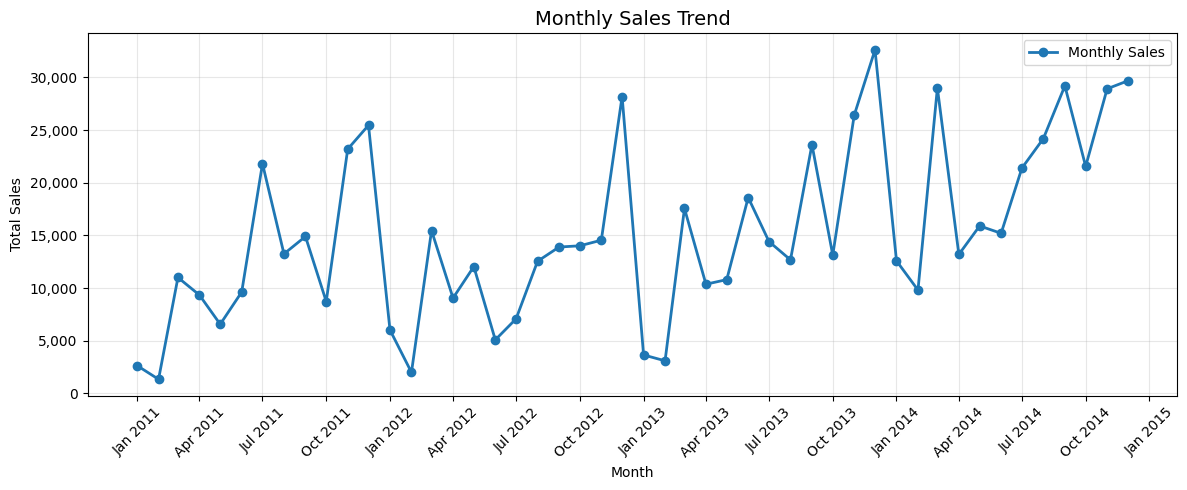

In [ ]:

# Monthly Sales Trend Visualization

import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import matplotlib.dates as mdates

plt.figure(figsize=(12, 5))

plt.plot(
    monthly_analysis["Order_Date"],
    monthly_analysis["Total_Sales"],
    marker="o",
    linewidth=2,
    label="Monthly Sales"
)

plt.title("Monthly Sales Trend", fontsize=14)
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.gca().yaxis.set_major_formatter(
    ticker.StrMethodFormatter("{x:,.0f}")
)
plt.gca().xaxis.set_major_locator(mdates.MonthLocator(interval=3))
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))

plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


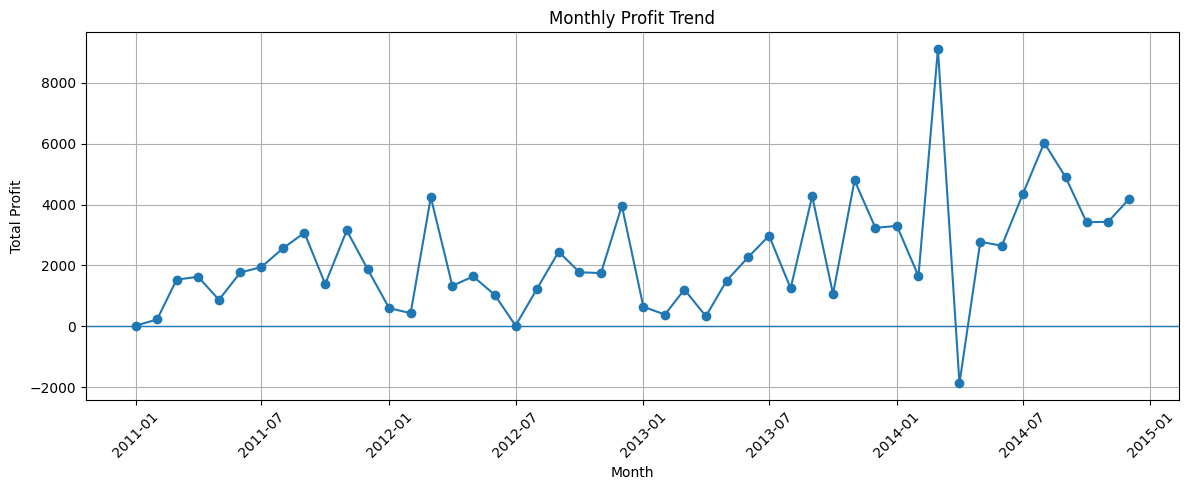

In [ ]:
# Monthly Profit Trend Visualization

plt.figure(figsize=(12, 5))

plt.plot(
    monthly_analysis["Order_Date"],
    monthly_analysis["Total_Profit"],
    marker="o"
)

plt.axhline(0, linewidth=1)

plt.title("Monthly Profit Trend")
plt.xlabel("Month")
plt.ylabel("Total Profit")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()

plt.show()

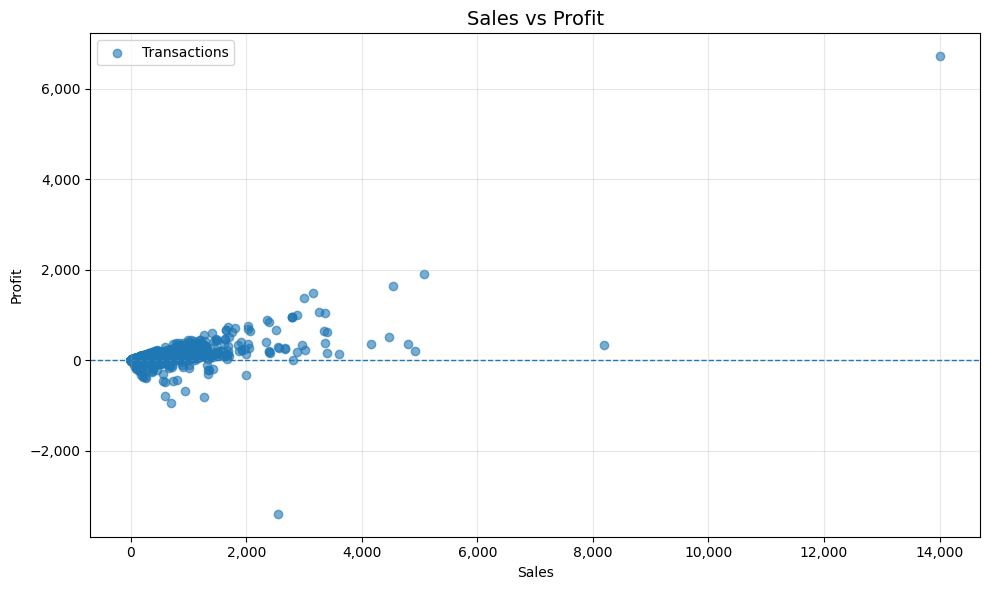

In [ ]:

# Sales vs Profit Visualization

import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

plt.figure(figsize=(10, 6))

plt.scatter(
    df["Sales"],
    df["Profit"],
    alpha=0.6,
    label="Transactions"
)

plt.title("Sales vs Profit", fontsize=14)
plt.xlabel("Sales")
plt.ylabel("Profit")

plt.gca().xaxis.set_major_formatter(
    ticker.StrMethodFormatter("{x:,.0f}")
)
plt.gca().yaxis.set_major_formatter(
    ticker.StrMethodFormatter("{x:,.0f}")
)

plt.axhline(0, linewidth=1, linestyle="--")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


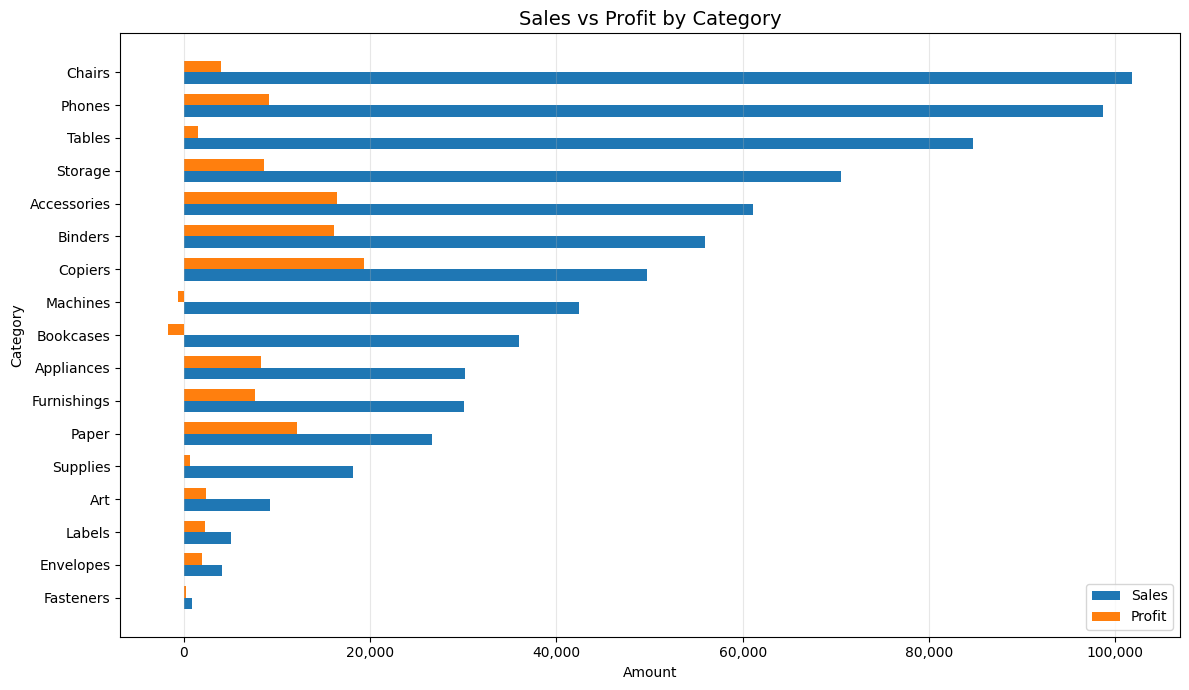

In [ ]:

# Sales and Profit by Category

import matplotlib.pyplot as plt
import numpy as np
import matplotlib.ticker as ticker

category_plot = category_analysis.sort_values(
    "Total_Sales", ascending=True
).copy()

y = np.arange(len(category_plot))
bar_height = 0.35

plt.figure(figsize=(12, 7))

plt.barh(
    y - bar_height / 2,
    category_plot["Total_Sales"],
    height=bar_height,
    label="Sales"
)

plt.barh(
    y + bar_height / 2,
    category_plot["Total_Profit"],
    height=bar_height,
    label="Profit"
)

plt.yticks(y, category_plot["Category"])
plt.title("Sales vs Profit by Category", fontsize=14)
plt.xlabel("Amount")
plt.ylabel("Category")

plt.gca().xaxis.set_major_formatter(
    ticker.StrMethodFormatter("{x:,.0f}")
)

plt.legend()
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()



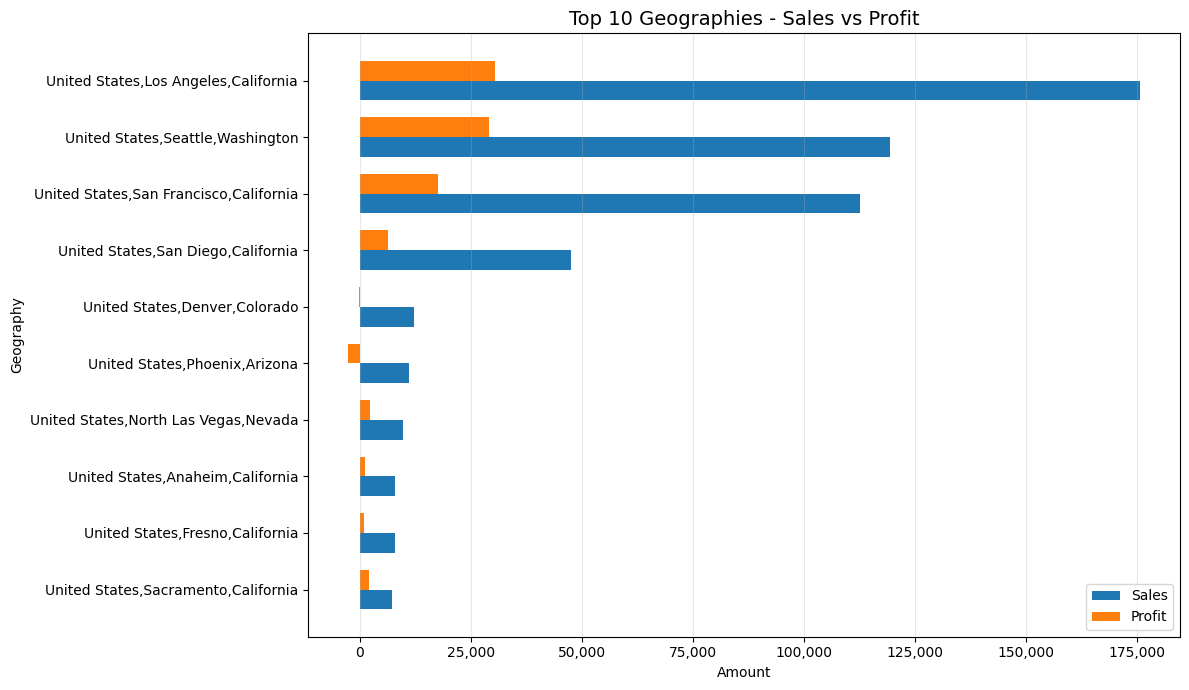

In [ ]:

# Top 10 Geographies - Sales vs Profit

import matplotlib.pyplot as plt
import numpy as np
import matplotlib.ticker as ticker

geography_plot = top_10_geography.sort_values(
    "Total_Sales", ascending=True
).copy()

y = np.arange(len(geography_plot))
bar_height = 0.35

plt.figure(figsize=(12, 7))

plt.barh(
    y - bar_height / 2,
    geography_plot["Total_Sales"],
    height=bar_height,
    label="Sales"
)

plt.barh(
    y + bar_height / 2,
    geography_plot["Total_Profit"],
    height=bar_height,
    label="Profit"
)

plt.yticks(y, geography_plot["Geography"])
plt.title("Top 10 Geographies - Sales vs Profit", fontsize=14)
plt.xlabel("Amount")
plt.ylabel("Geography")

plt.gca().xaxis.set_major_formatter(
    ticker.StrMethodFormatter("{x:,.0f}")
)

plt.legend()
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()


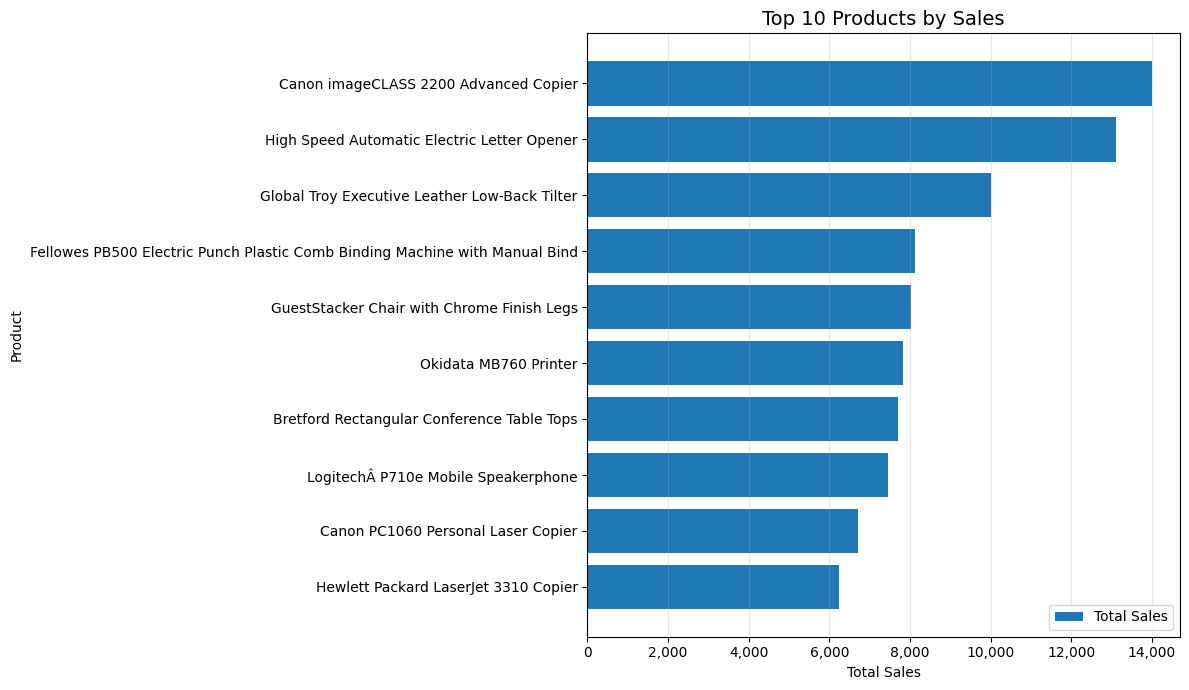

In [ ]:

# Top 10 Products by Sales

import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

product_plot = top_10_products.sort_values(
    "Total_Sales", ascending=True
).copy()

plt.figure(figsize=(12, 7))

plt.barh(
    product_plot["Product_Name"],
    product_plot["Total_Sales"],
    label="Total Sales"
)

plt.title("Top 10 Products by Sales", fontsize=14)
plt.xlabel("Total Sales")
plt.ylabel("Product")

plt.gca().xaxis.set_major_formatter(
    ticker.StrMethodFormatter("{x:,.0f}")
)

plt.grid(axis="x", alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


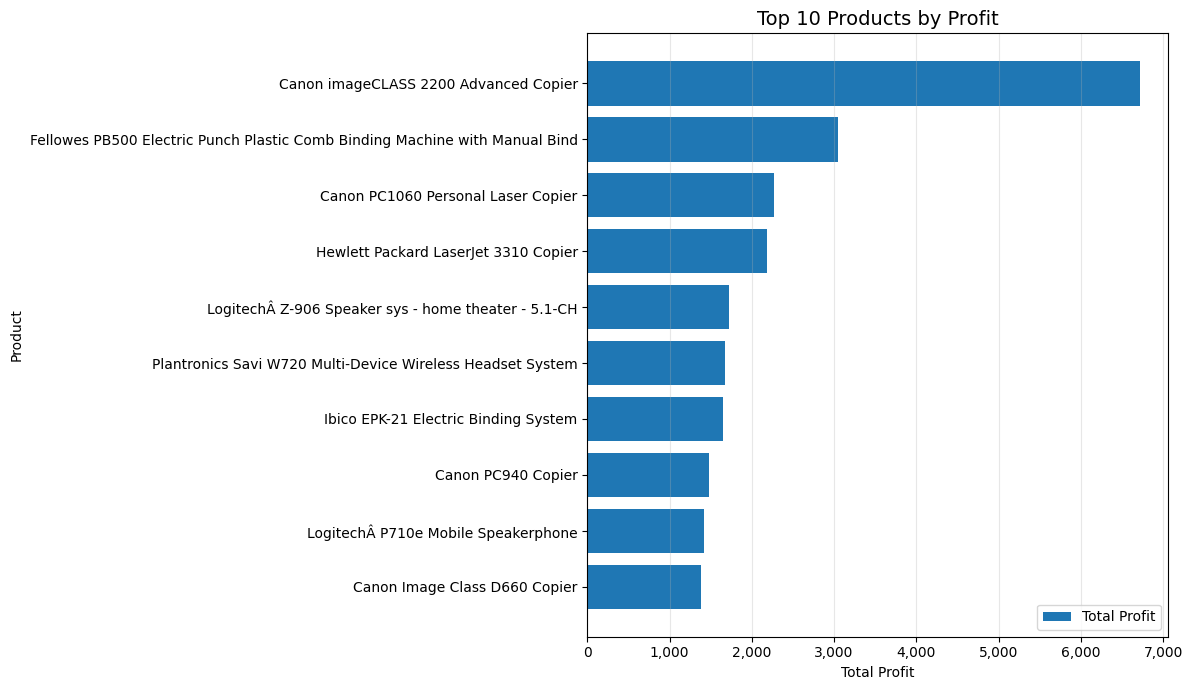

In [ ]:

# Top 10 Products by Profit

import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

profit_product_plot = (
    product_analysis
    .nlargest(10, "Total_Profit")
    .sort_values("Total_Profit", ascending=True)
    .copy()
)

plt.figure(figsize=(12, 7))

plt.barh(
    profit_product_plot["Product_Name"],
    profit_product_plot["Total_Profit"],
    label="Total Profit"
)

plt.title("Top 10 Products by Profit", fontsize=14)
plt.xlabel("Total Profit")
plt.ylabel("Product")

plt.gca().xaxis.set_major_formatter(
    ticker.StrMethodFormatter("{x:,.0f}")
)

plt.grid(axis="x", alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


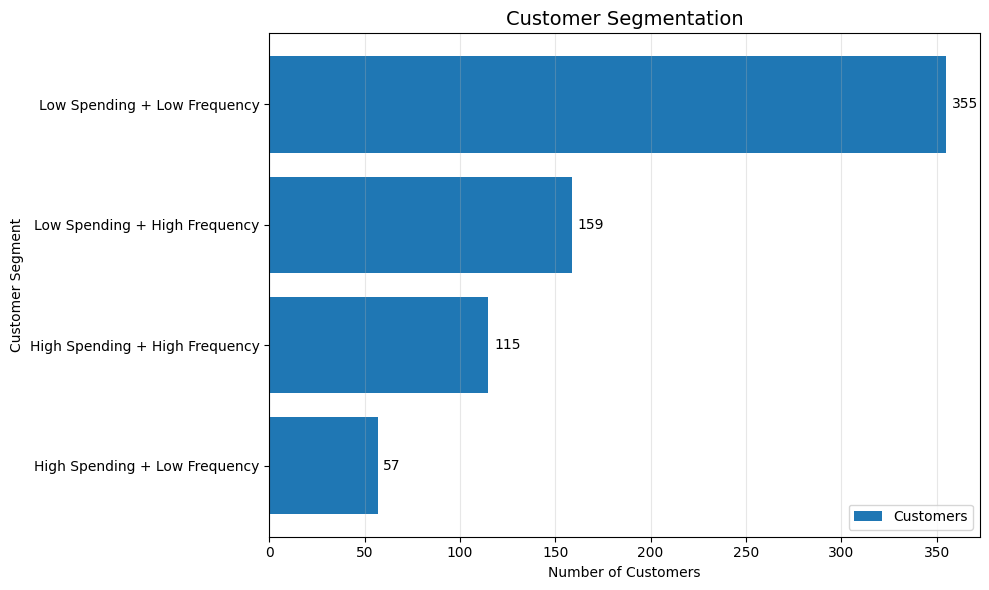

In [ ]:

# Customer Segmentation Visualization

import matplotlib.pyplot as plt

segment_plot = (
    customer_segments["Segment"]
    .value_counts()
    .sort_values(ascending=True)
)

plt.figure(figsize=(10, 6))

bars = plt.barh(
    segment_plot.index,
    segment_plot.values,
    label="Customers"
)

plt.bar_label(bars, padding=4, fmt="%.0f")

plt.title("Customer Segmentation", fontsize=14)
plt.xlabel("Number of Customers")
plt.ylabel("Customer Segment")
plt.grid(axis="x", alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


In [ ]:

# CSV and JSON File Handling

import os
import pandas as pd

output_dir = "finance_analyzer_output"
os.makedirs(output_dir, exist_ok=True)

# Exclude email addresses from exported files
export_df = df.drop(columns=["Email_ID"], errors="ignore").copy()

csv_path = os.path.join(output_dir, "cleaned_transactions.csv")
json_path = os.path.join(output_dir, "cleaned_transactions.json")

# Export the cleaned dataset
export_df.to_csv(csv_path, index=False)
export_df.to_json(json_path, orient="records", date_format="iso", indent=2)

# Read the saved files
csv_data = pd.read_csv(csv_path)
json_data = pd.read_json(json_path)

print("CSV file saved:", os.path.exists(csv_path))
print("JSON file saved:", os.path.exists(json_path))

print("\nOriginal export shape:", export_df.shape)
print("CSV data shape:", csv_data.shape)
print("JSON data shape:", json_data.shape)

print("\nCSV preview:")
display(csv_data.head())

print("\nJSON preview:")
display(json_data.head())


CSV file saved: True
JSON file saved: True

Original export shape: (3203, 9)
CSV data shape: (3203, 9)
JSON data shape: (3203, 9)

CSV preview:


,Order_ID,Order_Date,Ship_Date,Geography,Category,Product_Name,Sales,Quantity,Profit
0,CA-2013-138688,2013-06-13,2013-06-17,"United States,Los Angeles,California",Labels,Self-Adhesive Address Labels for Typewriters b...,14.620,2,6.8714
1,CA-2011-115812,2011-06-09,2011-06-14,"United States,Los Angeles,California",Furnishings,Eldon Expressions Wood and Plastic Desk Access...,48.860,7,14.1694
2,CA-2011-115812,2011-06-09,2011-06-14,"United States,Los Angeles,California",Art,Newell 322,7.280,4,1.9656
3,CA-2011-115812,2011-06-09,2011-06-14,"United States,Los Angeles,California",Phones,Mitel 5320 IP Phone VoIP phone,907.152,4,90.7152
4,CA-2011-115812,2011-06-09,2011-06-14,"United States,Los Angeles,California",Binders,DXL Angle-View Binders with Locking Rings by S...,18.504,3,5.7825



JSON preview:


,Order_ID,Order_Date,Ship_Date,Geography,Category,Product_Name,Sales,Quantity,Profit
0,CA-2013-138688,2013-06-13T00:00:00.000,2013-06-17T00:00:00.000,"United States,Los Angeles,California",Labels,Self-Adhesive Address Labels for Typewriters b...,14.620,2,6.8714
1,CA-2011-115812,2011-06-09T00:00:00.000,2011-06-14T00:00:00.000,"United States,Los Angeles,California",Furnishings,Eldon Expressions Wood and Plastic Desk Access...,48.860,7,14.1694
2,CA-2011-115812,2011-06-09T00:00:00.000,2011-06-14T00:00:00.000,"United States,Los Angeles,California",Art,Newell 322,7.280,4,1.9656
3,CA-2011-115812,2011-06-09T00:00:00.000,2011-06-14T00:00:00.000,"United States,Los Angeles,California",Phones,Mitel 5320 IP Phone VoIP phone,907.152,4,90.7152
4,CA-2011-115812,2011-06-09T00:00:00.000,2011-06-14T00:00:00.000,"United States,Los Angeles,California",Binders,DXL Angle-View Binders with Locking Rings by S...,18.504,3,5.7825


In [ ]:

# Transaction Class

class Transaction:
    def __init__(
        self, order_id, order_date, ship_date,
        geography, category, product_name,
        sales, quantity, profit
    ):
        self.order_id = order_id
        self.order_date = order_date
        self.ship_date = ship_date
        self.geography = geography
        self.category = category
        self.product_name = product_name
        self.sales = float(sales)
        self.quantity = int(quantity)
        self.profit = float(profit)

    def calculate_profit_margin(self):
        if self.sales == 0:
            return 0.0
        return (self.profit / self.sales) * 100

    def to_dict(self):
        return {
            "Order_ID": self.order_id,
            "Order_Date": str(self.order_date),
            "Ship_Date": str(self.ship_date),
            "Geography": self.geography,
            "Category": self.category,
            "Product_Name": self.product_name,
            "Sales": self.sales,
            "Quantity": self.quantity,
            "Profit": self.profit
        }


# Create an object using the first CSV record
first_record = csv_data.iloc[0]

transaction = Transaction(
    first_record["Order_ID"],
    first_record["Order_Date"],
    first_record["Ship_Date"],
    first_record["Geography"],
    first_record["Category"],
    first_record["Product_Name"],
    first_record["Sales"],
    first_record["Quantity"],
    first_record["Profit"]
)

print("Transaction Details:")
print(transaction.to_dict())

print("\nProfit Margin:", round(
    transaction.calculate_profit_margin(), 2
), "%")


Transaction Details:
{'Order_ID': 'CA-2013-138688', 'Order_Date': '2013-06-13', 'Ship_Date': '2013-06-17', 'Geography': 'United States,Los Angeles,California', 'Category': 'Labels', 'Product_Name': 'Self-Adhesive Address Labels for Typewriters by Universal', 'Sales': 14.62, 'Quantity': 2, 'Profit': 6.8714}

Profit Margin: 47.0 %


In [ ]:

# FileHandler Class

import os
import pandas as pd

class FileHandler:
    def read_csv(self, file_path):
        if not os.path.exists(file_path):
            raise FileNotFoundError(f"File not found: {file_path}")
        return pd.read_csv(file_path)

    def read_json(self, file_path):
        if not os.path.exists(file_path):
            raise FileNotFoundError(f"File not found: {file_path}")
        return pd.read_json(file_path)

    def write_csv(self, data, file_path):
        data.to_csv(file_path, index=False)
        print("CSV file saved successfully:", file_path)

    def write_json(self, data, file_path):
        data.to_json(
            file_path,
            orient="records",
            date_format="iso",
            indent=2
        )
        print("JSON file saved successfully:", file_path)


# Create a FileHandler object
file_handler = FileHandler()

# Read the CSV file
loaded_data = file_handler.read_csv(csv_path)

print("FileHandler class test")
print("Rows loaded:", len(loaded_data))
print("Columns loaded:", len(loaded_data.columns))
print("\nFirst 5 records:")
display(loaded_data.head())


FileHandler class test
Rows loaded: 3203
Columns loaded: 9

First 5 records:


,Order_ID,Order_Date,Ship_Date,Geography,Category,Product_Name,Sales,Quantity,Profit
0,CA-2013-138688,2013-06-13,2013-06-17,"United States,Los Angeles,California",Labels,Self-Adhesive Address Labels for Typewriters b...,14.620,2,6.8714
1,CA-2011-115812,2011-06-09,2011-06-14,"United States,Los Angeles,California",Furnishings,Eldon Expressions Wood and Plastic Desk Access...,48.860,7,14.1694
2,CA-2011-115812,2011-06-09,2011-06-14,"United States,Los Angeles,California",Art,Newell 322,7.280,4,1.9656
3,CA-2011-115812,2011-06-09,2011-06-14,"United States,Los Angeles,California",Phones,Mitel 5320 IP Phone VoIP phone,907.152,4,90.7152
4,CA-2011-115812,2011-06-09,2011-06-14,"United States,Los Angeles,California",Binders,DXL Angle-View Binders with Locking Rings by S...,18.504,3,5.7825


In [ ]:

# DataManager Class

class DataManager:
    def __init__(self, data):
        self.data = data.copy()

    def get_summary(self):
        return {
            "Total Transactions": len(self.data),
            "Total Sales": self.data["Sales"].sum(),
            "Total Profit": self.data["Profit"].sum(),
            "Total Quantity": self.data["Quantity"].sum(),
            "Average Sales": self.data["Sales"].mean()
        }

    def get_category_summary(self):
        return (
            self.data.groupby("Category")
            .agg(
                Total_Sales=("Sales", "sum"),
                Total_Profit=("Profit", "sum"),
                Total_Quantity=("Quantity", "sum")
            )
            .sort_values("Total_Sales", ascending=False)
            .reset_index()
        )

    def get_top_transactions(self, n=5):
        return self.data.nlargest(n, "Sales")


# Create a DataManager object
data_manager = DataManager(loaded_data)

print("Overall Transaction Summary:")
for key, value in data_manager.get_summary().items():
    print(f"{key}: {value:,.2f}" if isinstance(value, (int, float)) else f"{key}: {value}")

print("\nCategory Summary:")
display(data_manager.get_category_summary())

print("\nTop 5 Transactions by Sales:")
display(data_manager.get_top_transactions())


Overall Transaction Summary:
Total Transactions: 3,203.00
Total Sales: 725,457.82
Total Profit: 108,418.45
Total Quantity: 12264
Average Sales: 226.49

Category Summary:


,Category,Total_Sales,Total_Profit,Total_Quantity
0,Chairs,101781.3280,4027.5843,734
1,Phones,98684.3520,9110.7426,1066
2,Tables,84754.5620,1482.6073,481
3,Storage,70532.8520,8645.3222,1039
4,Accessories,61114.1160,16484.5983,1032
5,Binders,55961.1130,16096.8016,1868
6,Copiers,49749.2420,19327.2351,88
7,Machines,42444.1220,-618.9264,147
8,Bookcases,36004.1235,-1646.5117,306
9,Appliances,30236.3360,8261.2699,492



Top 5 Transactions by Sales:


,Order_ID,Order_Date,Ship_Date,Geography,Category,Product_Name,Sales,Quantity,Profit
2663,CA-2014-140151,2014-03-24,2014-03-26,"United States,Seattle,Washington",Copiers,Canon imageCLASS 2200 Advanced Copier,13999.960,4,6719.9808
799,CA-2011-143917,2011-07-25,2011-07-27,"United States,San Francisco,California",Supplies,High Speed Automatic Electric Letter Opener,8187.650,5,327.5060
2846,CA-2014-135909,2014-10-14,2014-10-21,"United States,Sacramento,California",Binders,Fellowes PB500 Electric Punch Plastic Comb Bin...,5083.960,5,1906.4850
1913,CA-2013-136301,2013-03-14,2013-03-16,"United States,San Francisco,California",Supplies,High Speed Automatic Electric Letter Opener,4912.590,3,196.5036
1319,CA-2014-149881,2014-04-02,2014-04-04,"United States,San Francisco,California",Machines,Cubify CubeX 3D Printer Double Head Print,4799.984,2,359.9988


In [ ]:

# FinanceAnalyzer Class

class FinanceAnalyzer:
    def __init__(self, data):
        self.data = data.copy()

    def calculate_total_sales(self):
        return self.data["Sales"].sum()

    def calculate_total_profit(self):
        return self.data["Profit"].sum()

    def calculate_profit_margin(self):
        total_sales = self.calculate_total_sales()
        if total_sales == 0:
            return 0.0
        return (self.calculate_total_profit() / total_sales) * 100

    def get_best_category(self):
        category_profit = self.data.groupby("Category")["Profit"].sum()
        return category_profit.idxmax(), category_profit.max()

    def get_worst_category(self):
        category_profit = self.data.groupby("Category")["Profit"].sum()
        return category_profit.idxmin(), category_profit.min()

    def get_financial_summary(self):
        best_category, best_profit = self.get_best_category()
        worst_category, worst_profit = self.get_worst_category()

        return {
            "Total Sales": self.calculate_total_sales(),
            "Total Profit": self.calculate_total_profit(),
            "Overall Profit Margin (%)": self.calculate_profit_margin(),
            "Most Profitable Category": best_category,
            "Highest Category Profit": best_profit,
            "Least Profitable Category": worst_category,
            "Lowest Category Profit": worst_profit
        }


# Create a FinanceAnalyzer object
finance_analyzer = FinanceAnalyzer(loaded_data)

print("Financial Analysis Report")
print("-" * 35)

for key, value in finance_analyzer.get_financial_summary().items():
    if isinstance(value, (int, float)):
        print(f"{key}: {value:,.2f}")
    else:
        print(f"{key}: {value}")


Financial Analysis Report
-----------------------------------
Total Sales: 725,457.82
Total Profit: 108,418.45
Overall Profit Margin (%): 14.94
Most Profitable Category: Copiers
Highest Category Profit: 19,327.24
Least Profitable Category: Bookcases
Lowest Category Profit: -1,646.51


In [ ]:

# CategoryAnalyzer Class

class CategoryAnalyzer:
    def __init__(self, data):
        self.data = data.copy()

    def analyze_categories(self):
        result = (
            self.data.groupby("Category")
            .agg(
                Total_Sales=("Sales", "sum"),
                Total_Profit=("Profit", "sum"),
                Total_Quantity=("Quantity", "sum"),
                Transaction_Count=("Order_ID", "count")
            )
            .reset_index()
        )

        result["Profit_Margin (%)"] = np.where(
            result["Total_Sales"] != 0,
            result["Total_Profit"] / result["Total_Sales"] * 100,
            0
        )

        return result.sort_values(
            "Total_Sales", ascending=False
        ).reset_index(drop=True)

    def get_top_categories(self, n=5):
        return self.analyze_categories().head(n)

    def get_loss_making_categories(self):
        result = self.analyze_categories()
        return result[result["Total_Profit"] < 0]


# Create a CategoryAnalyzer object
category_analyzer = CategoryAnalyzer(loaded_data)

print("Category Analysis")
print("-" * 35)

print("\nTop 5 Categories by Sales:")
display(category_analyzer.get_top_categories())

print("\nCategories with Negative Profit:")
display(category_analyzer.get_loss_making_categories())


Category Analysis
-----------------------------------

Top 5 Categories by Sales:


,Category,Total_Sales,Total_Profit,Total_Quantity,Transaction_Count,Profit_Margin (%)
0,Chairs,101781.328,4027.5843,734,207,3.957095
1,Phones,98684.352,9110.7426,1066,277,9.232206
2,Tables,84754.562,1482.6073,481,116,1.749295
3,Storage,70532.852,8645.3222,1039,266,12.257157
4,Accessories,61114.116,16484.5983,1032,258,26.973471



Categories with Negative Profit:


,Category,Total_Sales,Total_Profit,Total_Quantity,Transaction_Count,Profit_Margin (%)
7,Machines,42444.1220,-618.9264,147,39,-1.458215
8,Bookcases,36004.1235,-1646.5117,306,80,-4.573120


In [ ]:

# ProductAnalyzer Class

class ProductAnalyzer:
    def __init__(self, data):
        self.data = data.copy()

    def analyze_products(self):
        result = (
            self.data.groupby("Product_Name")
            .agg(
                Total_Sales=("Sales", "sum"),
                Total_Profit=("Profit", "sum"),
                Total_Quantity=("Quantity", "sum"),
                Transaction_Count=("Order_ID", "count")
            )
            .reset_index()
        )

        result["Profit_Margin (%)"] = np.where(
            result["Total_Sales"] != 0,
            result["Total_Profit"] / result["Total_Sales"] * 100,
            0
        )

        return result

    def get_top_products_by_sales(self, n=5):
        return self.analyze_products().nlargest(n, "Total_Sales")

    def get_top_products_by_profit(self, n=5):
        return self.analyze_products().nlargest(n, "Total_Profit")

    def get_loss_making_products(self):
        result = self.analyze_products()
        return result[result["Total_Profit"] < 0].sort_values(
            "Total_Profit"
        )


# Create a ProductAnalyzer object
product_analyzer = ProductAnalyzer(loaded_data)

print("Top 5 Products by Sales:")
display(product_analyzer.get_top_products_by_sales())

print("\nTop 5 Products by Profit:")
display(product_analyzer.get_top_products_by_profit())

print("\nProducts with Negative Profit:")
display(product_analyzer.get_loss_making_products().head(10))


Top 5 Products by Sales:


,Product_Name,Total_Sales,Total_Profit,Total_Quantity,Transaction_Count,Profit_Margin (%)
328,Canon imageCLASS 2200 Advanced Copier,13999.960,6719.9808,4,1,48.00
661,High Speed Automatic Electric Letter Opener,13100.240,524.0096,8,2,4.00
627,Global Troy Executive Leather Low-Back Tilter,10019.600,626.2250,25,7,6.25
524,Fellowes PB500 Electric Punch Plastic Comb Bin...,8134.336,3050.3760,8,3,37.50
642,GuestStacker Chair with Chrome Finish Legs,8030.016,803.0016,27,6,10.00



Top 5 Products by Profit:


,Product_Name,Total_Sales,Total_Profit,Total_Quantity,Transaction_Count,Profit_Margin (%)
328,Canon imageCLASS 2200 Advanced Copier,13999.960,6719.9808,4,1,48.00
524,Fellowes PB500 Electric Punch Plastic Comb Bin...,8134.336,3050.3760,8,3,37.50
325,Canon PC1060 Personal Laser Copier,6719.904,2267.9676,12,3,33.75
659,Hewlett Packard LaserJet 3310 Copier,6239.896,2183.9636,13,3,35.00
831,LogitechÂ Z-906 Speaker sys - home theater - 5...,4289.870,1715.9480,13,3,40.00



Products with Negative Profit:


,Product_Name,Total_Sales,Total_Profit,Total_Quantity,Transaction_Count,Profit_Margin (%)
793,Lexmark MX611dhe Monochrome Laser Printer,2549.985,-3399.9800,5,1,-133.333333
1483,Zebra GK420t Direct Thermal/Thermal Transfer P...,703.710,-938.2800,6,1,-133.333333
960,O'Sullivan 4-Shelf Bookcase in Odessa Pine,1808.651,-802.0974,26,4,-44.347826
670,Hon 2090 Â“Pillow SoftÂ” Series Mid Back Swive...,3371.760,-547.9110,15,4,-16.250000
139,"Atlantic Metals Mobile 4-Shelf Bookcases, Cust...",2261.889,-491.7150,14,3,-21.739130
259,Bestar Classic Bookcase,1179.882,-439.9560,20,5,-37.288136
345,"Chromcraft 48"" x 96"" Racetrack Double Pedestal...",1314.624,-436.0704,7,2,-33.170732
300,Bretford Â“Just In TimeÂ” Height-Adjustable Mu...,5008.800,-425.7480,14,3,-8.500000
552,GBC DocuBind 300 Electric Binding Machine,1788.332,-399.7448,8,2,-22.352941
1003,Panasonic KX MC6040 Color Laser Multifunction ...,269.970,-386.9570,2,1,-143.333333


In [ ]:

# GeographyAnalyzer Class

class GeographyAnalyzer:
    def __init__(self, data):
        self.data = data.copy()

    def analyze_geography(self):
        result = (
            self.data.groupby("Geography")
            .agg(
                Total_Sales=("Sales", "sum"),
                Total_Profit=("Profit", "sum"),
                Total_Quantity=("Quantity", "sum"),
                Transaction_Count=("Order_ID", "count")
            )
            .reset_index()
        )

        result["Profit_Margin (%)"] = np.where(
            result["Total_Sales"] != 0,
            result["Total_Profit"] / result["Total_Sales"] * 100,
            0
        )

        return result.sort_values(
            "Total_Sales", ascending=False
        ).reset_index(drop=True)

    def get_top_geographies(self, n=10):
        return self.analyze_geography().head(n)

    def get_least_profitable_geographies(self, n=10):
        return self.analyze_geography().nsmallest(
            n, "Total_Profit"
        )


# Create a GeographyAnalyzer object
geography_analyzer = GeographyAnalyzer(loaded_data)

print("Top 10 Geographies by Sales:")
display(geography_analyzer.get_top_geographies())

print("\n10 Least Profitable Geographies:")
display(geography_analyzer.get_least_profitable_geographies())


Top 10 Geographies by Sales:


,Geography,Total_Sales,Total_Profit,Total_Quantity,Transaction_Count,Profit_Margin (%)
0,"United States,Los Angeles,California",175851.3410,30440.7579,2877,747,17.310507
1,"United States,Seattle,Washington",119540.7420,29156.0967,1590,428,24.390092
2,"United States,San Francisco,California",112669.0920,17507.3854,1935,510,15.538765
3,"United States,San Diego,California",47521.0290,6377.1960,670,170,13.419735
4,"United States,Denver,Colorado",12198.7930,-244.9200,164,44,-2.007740
5,"United States,Phoenix,Arizona",11000.2570,-2790.8832,224,63,-25.371073
6,"United States,North Las Vegas,Nevada",9801.0020,2247.6899,58,16,22.933266
7,"United States,Anaheim,California",7986.8700,1234.0036,112,27,15.450403
8,"United States,Fresno,California",7888.5285,948.2681,106,26,12.020849
9,"United States,Sacramento,California",7311.2780,2069.6859,36,13,28.308128



10 Least Profitable Geographies:


,Geography,Total_Sales,Total_Profit,Total_Quantity,Transaction_Count,Profit_Margin (%)
15,"United States,Louisville,Colorado",5070.416,-3406.2095,90,24,-67.178107
5,"United States,Phoenix,Arizona",11000.257,-2790.8832,224,63,-25.371073
26,"United States,Colorado Springs,Colorado",3694.009,-956.6841,110,25,-25.898261
52,"United States,Pueblo,Colorado",1686.938,-900.9719,42,8,-53.408714
13,"United States,Springfield,Oregon",5761.265,-853.3086,163,38,-14.811133
21,"United States,Aurora,Colorado",4083.510,-797.0190,130,34,-19.517988
23,"United States,Mesa,Arizona",4037.740,-559.2314,128,28,-13.850109
90,"United States,Yuma,Arizona",840.865,-465.9909,22,4,-55.418040
64,"United States,Salem,Oregon",1404.695,-262.3311,101,27,-18.675307
87,"United States,Fort Collins,Colorado",935.252,-252.6926,20,7,-27.018664


In [ ]:

# TimeAnalyzer Class

class TimeAnalyzer:
    def __init__(self, data):
        self.data = data.copy()
        self.data["Order_Date"] = pd.to_datetime(
            self.data["Order_Date"], errors="coerce"
        )
        self.data = self.data.dropna(subset=["Order_Date"])

    def analyze_monthly(self):
        monthly = (
            self.data.set_index("Order_Date")
            .resample("MS")
            .agg(
                Total_Sales=("Sales", "sum"),
                Total_Profit=("Profit", "sum"),
                Total_Quantity=("Quantity", "sum")
            )
            .reset_index()
        )
        return monthly

    def analyze_yearly(self):
        yearly = (
            self.data.set_index("Order_Date")
            .resample("YS")
            .agg(
                Total_Sales=("Sales", "sum"),
                Total_Profit=("Profit", "sum"),
                Total_Quantity=("Quantity", "sum")
            )
            .reset_index()
        )
        yearly["Year"] = yearly["Order_Date"].dt.year
        return yearly.drop(columns=["Order_Date"])

    def get_best_month(self):
        monthly = self.analyze_monthly()
        if monthly.empty:
            return None
        return monthly.loc[monthly["Total_Sales"].idxmax()]

    def get_best_year(self):
        yearly = self.analyze_yearly()
        if yearly.empty:
            return None
        return yearly.loc[yearly["Total_Sales"].idxmax()]


# Create a TimeAnalyzer object
time_analyzer = TimeAnalyzer(loaded_data)

print("Yearly Sales and Profit:")
display(time_analyzer.analyze_yearly())

print("\nFirst 12 Months:")
display(time_analyzer.analyze_monthly().head(12))

best_month = time_analyzer.get_best_month()
best_year = time_analyzer.get_best_year()

print("\nMonth with Highest Sales:")
print(best_month.to_dict() if best_month is not None else "No data available")

print("\nYear with Highest Sales:")
print(best_year.to_dict() if best_year is not None else "No data available")


Yearly Sales and Profit:


,Total_Sales,Total_Profit,Total_Quantity,Year
0,147883.0330,20065.6912,2531,2011
1,139966.2495,20492.1947,2438,2012
2,186976.0165,23959.9374,3010,2013
3,250632.5255,43900.6256,4285,2014



First 12 Months:


,Order_Date,Total_Sales,Total_Profit,Total_Quantity
0,2011-01-01,2648.0570,20.9733,62
1,2011-02-01,1348.6220,228.8282,49
2,2011-03-01,11008.8980,1534.2273,150
3,2011-04-01,9343.4870,1629.4545,179
4,2011-05-01,6570.4380,873.5640,141
5,2011-06-01,9629.4220,1771.8152,136
6,2011-07-01,21808.5530,1946.6828,260
7,2011-08-01,13248.2310,2560.9044,246
8,2011-09-01,14900.5370,3075.5227,274
9,2011-10-01,8728.7580,1391.2655,233



Month with Highest Sales:
{'Order_Date': Timestamp('2013-12-01 00:00:00'), 'Total_Sales': 32617.34, 'Total_Profit': 3235.6103, 'Total_Quantity': 568}

Year with Highest Sales:
{'Total_Sales': 250632.5255, 'Total_Profit': 43900.6256, 'Total_Quantity': 4285.0, 'Year': 2014.0}


In [ ]:

# MLModel Class - Random Forest Regressor

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

class MLModel:
    def __init__(self, data):
        self.data = data.copy()
        self.model = None
        self.features = [
            "Quantity", "Year", "Month", "Day",
            "Category_Code", "Geography_Code", "Product_Code"
        ]

    def prepare_data(self):
        data = self.data.copy()
        data["Order_Date"] = pd.to_datetime(
            data["Order_Date"], errors="coerce"
        )

        data = data.dropna(
            subset=["Order_Date", "Sales", "Quantity", "Profit",
                    "Category", "Geography", "Product_Name"]
        ).copy()

        data["Year"] = data["Order_Date"].dt.year
        data["Month"] = data["Order_Date"].dt.month
        data["Day"] = data["Order_Date"].dt.day

        data["Category_Code"] = data["Category"].astype("category").cat.codes
        data["Geography_Code"] = data["Geography"].astype("category").cat.codes
        data["Product_Code"] = data["Product_Name"].astype("category").cat.codes

        return data

    def train_and_evaluate(self):
        data = self.prepare_data().sort_values("Order_Date").reset_index(drop=True)

        if len(data) < 10:
            raise ValueError("Not enough valid records for model training.")

        split_index = int(len(data) * 0.8)

        train_data = data.iloc[:split_index]
        test_data = data.iloc[split_index:]

        X_train = train_data[self.features]
        y_train = train_data["Sales"]
        X_test = test_data[self.features]
        y_test = test_data["Sales"]

        self.model = RandomForestRegressor(
            n_estimators=100,
            random_state=42,
            n_jobs=-1
        )
        self.model.fit(X_train, y_train)

        predictions = self.model.predict(X_test)

        mae = mean_absolute_error(y_test, predictions)
        rmse = np.sqrt(mean_squared_error(y_test, predictions))
        r2 = r2_score(y_test, predictions)

        results = {
            "Training Records": len(train_data),
            "Testing Records": len(test_data),
            "MAE": mae,
            "RMSE": rmse,
            "R2 Score": r2
        }

        return results, y_test.to_numpy(), predictions


# Create an MLModel object and evaluate the model
ml_model = MLModel(loaded_data)
model_results, actual_sales, predicted_sales = ml_model.train_and_evaluate()

print("Random Forest Regression Results")
print("-" * 40)

for key, value in model_results.items():
    if isinstance(value, (int, float, np.integer, np.floating)):
        print(f"{key}: {value:,.4f}")
    else:
        print(f"{key}: {value}")


Random Forest Regression Results
----------------------------------------
Training Records: 2,562.0000
Testing Records: 641.0000
MAE: 195.7268
RMSE: 383.7394
R2 Score: 0.1904


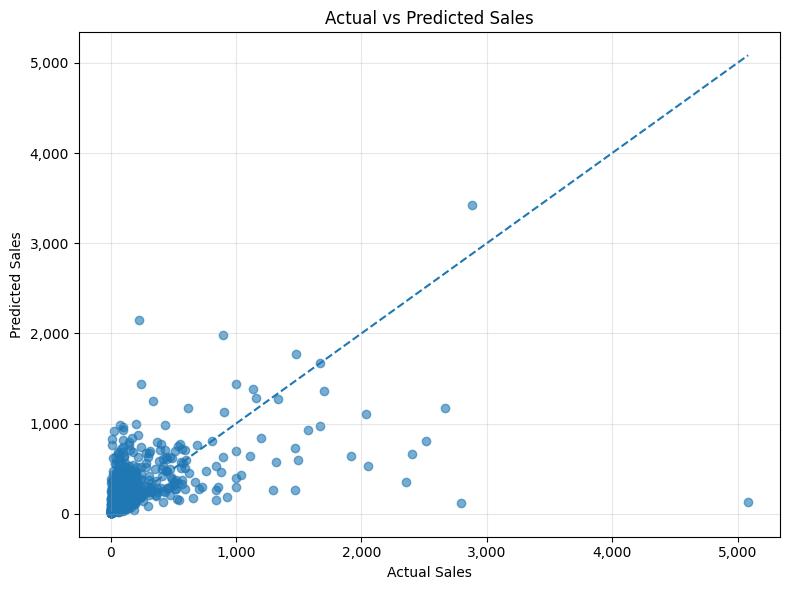

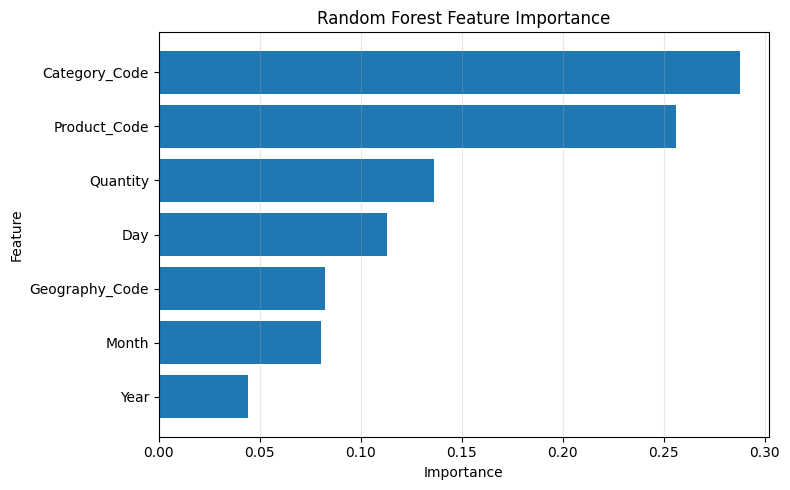

In [ ]:

# Visualizer Class

import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

class Visualizer:
    def plot_actual_vs_predicted(self, actual, predicted):
        plt.figure(figsize=(8, 6))
        plt.scatter(actual, predicted, alpha=0.6)

        minimum = min(np.min(actual), np.min(predicted))
        maximum = max(np.max(actual), np.max(predicted))
        plt.plot(
            [minimum, maximum],
            [minimum, maximum],
            linestyle="--"
        )

        plt.title("Actual vs Predicted Sales")
        plt.xlabel("Actual Sales")
        plt.ylabel("Predicted Sales")
        plt.gca().xaxis.set_major_formatter(
            ticker.StrMethodFormatter("{x:,.0f}")
        )
        plt.gca().yaxis.set_major_formatter(
            ticker.StrMethodFormatter("{x:,.0f}")
        )
        plt.grid(True, alpha=0.3)
        plt.tight_layout()
        plt.show()

    def plot_feature_importance(self, model, feature_names):
        importance = pd.DataFrame({
            "Feature": feature_names,
            "Importance": model.feature_importances_
        }).sort_values("Importance", ascending=True)

        plt.figure(figsize=(8, 5))
        plt.barh(importance["Feature"], importance["Importance"])
        plt.title("Random Forest Feature Importance")
        plt.xlabel("Importance")
        plt.ylabel("Feature")
        plt.grid(axis="x", alpha=0.3)
        plt.tight_layout()
        plt.show()


# Create a Visualizer object
visualizer = Visualizer()

visualizer.plot_actual_vs_predicted(
    actual_sales, predicted_sales
)

visualizer.plot_feature_importance(
    ml_model.model, ml_model.features
)


In [ ]:

# ReportGenerator Class

import os
from datetime import datetime

class ReportGenerator:
    def __init__(self, output_dir="finance_analyzer_output"):
        self.output_dir = output_dir
        os.makedirs(self.output_dir, exist_ok=True)

    def generate_report(self, financial_summary, model_results):
        report_path = os.path.join(
            self.output_dir, "finance_analysis_report.txt"
        )

        with open(report_path, "w", encoding="utf-8") as file:
            file.write("PERSONAL FINANCE ANALYZER\n")
            file.write("Sales Transaction Analysis Report\n")
            file.write("=" * 45 + "\n")
            file.write(
                f"Generated on: {datetime.now():%Y-%m-%d %H:%M:%S}\n\n"
            )

            file.write("FINANCIAL SUMMARY\n")
            file.write("-" * 25 + "\n")
            for key, value in financial_summary.items():
                if isinstance(value, (int, float, np.integer, np.floating)):
                    file.write(f"{key}: {value:,.2f}\n")
                else:
                    file.write(f"{key}: {value}\n")

            file.write("\nRANDOM FOREST MODEL EVALUATION\n")
            file.write("-" * 30 + "\n")
            for key, value in model_results.items():
                if isinstance(value, (int, float, np.integer, np.floating)):
                    file.write(f"{key}: {value:,.4f}\n")
                else:
                    file.write(f"{key}: {value}\n")

        return report_path


# Create a ReportGenerator object
report_generator = ReportGenerator()

report_path = report_generator.generate_report(
    finance_analyzer.get_financial_summary(),
    model_results
)

print("Report generated successfully:", os.path.exists(report_path))
print("Report location:", report_path)

with open(report_path, "r", encoding="utf-8") as file:
    print("\n" + file.read())



Report generated successfully: True
Report location: finance_analyzer_output/finance_analysis_report.txt

PERSONAL FINANCE ANALYZER
Sales Transaction Analysis Report
Generated on: 2026-11-01 18:08:27

FINANCIAL SUMMARY
-------------------------
Total Sales: 725,457.82
Total Profit: 108,418.45
Overall Profit Margin (%): 14.94
Most Profitable Category: Copiers
Highest Category Profit: 19,327.24
Least Profitable Category: Bookcases
Lowest Category Profit: -1,646.51

RANDOM FOREST MODEL EVALUATION
------------------------------
Training Records: 2,562.0000
Testing Records: 641.0000
MAE: 195.7268
RMSE: 383.7394
R2 Score: 0.1904



In [ ]:
!pip install -q streamlit plotly pyngrok

In [ ]:

%%writefile app.py
import streamlit as st
import pandas as pd
import numpy as np
import plotly.express as px

st.set_page_config(
    page_title="Amazon Sales Intelligence",
    page_icon="📊",
    layout="wide"
)

st.title("📊 Amazon Sales Intelligence")
st.caption("Interactive sales, profit and business performance dashboard")

st.sidebar.header("Dashboard Controls")
uploaded_file = st.sidebar.file_uploader(
    "Upload sales dataset",
    type=["csv", "xlsx", "json"]
)

@st.cache_data
def load_data(file, file_type):
    if file_type == "csv":
        data = pd.read_csv(file)
    elif file_type == "xlsx":
        data = pd.read_excel(file)
    else:
        data = pd.read_json(file)

    data.columns = [
        str(col).strip().replace(" ", "_")
        for col in data.columns
    ]

    required = [
        "Sales", "Profit", "Quantity", "Category",
        "Product_Name", "Geography", "Order_Date"
    ]

    missing = [col for col in required if col not in data.columns]
    if missing:
        raise ValueError("Missing columns: " + ", ".join(missing))

    for col in ["Sales", "Profit", "Quantity"]:
        data[col] = pd.to_numeric(data[col], errors="coerce")

    data["Order_Date"] = pd.to_datetime(
        data["Order_Date"], errors="coerce"
    )

    data = data.dropna(
        subset=["Sales", "Profit", "Quantity", "Order_Date"]
    )
    return data

if uploaded_file is None:
    st.info("Upload your cleaned_transactions.csv file using the sidebar.")
    st.stop()

try:
    file_type = uploaded_file.name.rsplit(".", 1)[-1].lower()
    df = load_data(uploaded_file, file_type)
except Exception as error:
    st.error(f"Unable to load dataset: {error}")
    st.stop()

if df.empty:
    st.error("No valid transaction records found.")
    st.stop()

st.sidebar.success(f"{len(df):,} transaction rows loaded")

minimum_date = df["Order_Date"].min().date()
maximum_date = df["Order_Date"].max().date()

date_range = st.sidebar.date_input(
    "Order date range",
    value=(minimum_date, maximum_date),
    min_value=minimum_date,
    max_value=maximum_date
)

if isinstance(date_range, (tuple, list)) and len(date_range) == 2:
    start_date, end_date = date_range
    filtered = df[
        df["Order_Date"].dt.date.between(start_date, end_date)
    ].copy()
else:
    filtered = df.copy()

if filtered.empty:
    st.warning("No records in the selected date range.")
    st.stop()

total_sales = filtered["Sales"].sum()
total_profit = filtered["Profit"].sum()
total_quantity = filtered["Quantity"].sum()
margin = total_profit / total_sales * 100 if total_sales else 0

st.subheader("Business Overview")
c1, c2, c3, c4 = st.columns(4)
c1.metric("Total Sales", f"{total_sales:,.2f}")
c2.metric("Total Profit", f"{total_profit:,.2f}")
c3.metric("Quantity Sold", f"{total_quantity:,.0f}")
c4.metric("Profit Margin", f"{margin:.2f}%")

tab1, tab2, tab3, tab4 = st.tabs([
    "Sales Trends", "Products", "Categories", "Geography"
])

with tab1:
    st.subheader("Monthly Sales and Profit")
    monthly = (
        filtered.set_index("Order_Date")
        .resample("MS")
        .agg(Sales=("Sales", "sum"), Profit=("Profit", "sum"))
        .reset_index()
    )
    fig = px.line(
        monthly, x="Order_Date", y=["Sales", "Profit"],
        markers=True, title="Monthly Sales and Profit"
    )
    st.plotly_chart(fig, use_container_width=True)

    yearly = (
        filtered.assign(Year=filtered["Order_Date"].dt.year)
        .groupby("Year", as_index=False)
        .agg(Sales=("Sales", "sum"), Profit=("Profit", "sum"))
    )
    st.subheader("Yearly Performance")
    st.dataframe(yearly, use_container_width=True)

with tab2:
    products = (
        filtered.groupby("Product_Name", as_index=False)
        .agg(
            Total_Sales=("Sales", "sum"),
            Total_Profit=("Profit", "sum"),
            Quantity_Sold=("Quantity", "sum")
        )
    )

    st.subheader("Top 10 Products by Sales")
    top_products = products.nlargest(10, "Total_Sales")
    fig = px.bar(
        top_products.sort_values("Total_Sales"),
        x="Total_Sales", y="Product_Name",
        orientation="h"
    )
    st.plotly_chart(fig, use_container_width=True)

    st.subheader("Lowest-Profit Products")
    st.dataframe(
        products.nsmallest(10, "Total_Profit"),
        use_container_width=True
    )

with tab3:
    categories = (
        filtered.groupby("Category", as_index=False)
        .agg(
            Total_Sales=("Sales", "sum"),
            Total_Profit=("Profit", "sum"),
            Quantity_Sold=("Quantity", "sum")
        )
    )
    fig = px.bar(
        categories.sort_values("Total_Sales"),
        x="Total_Sales", y="Category", orientation="h",
        color="Total_Profit",
        title="Category Sales and Profit"
    )
    st.plotly_chart(fig, use_container_width=True)
    st.dataframe(categories, use_container_width=True)

with tab4:
    geography = (
        filtered.groupby("Geography", as_index=False)
        .agg(
            Total_Sales=("Sales", "sum"),
            Total_Profit=("Profit", "sum"),
            Quantity_Sold=("Quantity", "sum")
        )
    )
    st.subheader("Top 10 Geographies by Sales")
    top_geo = geography.nlargest(10, "Total_Sales")
    fig = px.bar(
        top_geo.sort_values("Total_Sales"),
        x="Total_Sales", y="Geography", orientation="h"
    )
    st.plotly_chart(fig, use_container_width=True)
    st.subheader("Lowest-Profit Geographies")
    st.dataframe(
        geography.nsmallest(10, "Total_Profit"),
        use_container_width=True
    )

st.subheader("Transaction Records")
st.dataframe(filtered, use_container_width=True)

csv_data = filtered.to_csv(index=False).encode("utf-8")
json_data = filtered.to_json(
    orient="records", date_format="iso", indent=2
).encode("utf-8")

d1, d2 = st.columns(2)
d1.download_button(
    "Download filtered CSV", csv_data,
    "filtered_sales.csv", "text/csv"
)
d2.download_button(
    "Download filtered JSON", json_data,
    "filtered_sales.json", "application/json"
)

st.caption("Analytics are based on the uploaded dataset, not a live connection to Amazon.")


Writing app.py


In [ ]:

%%writefile app.py
import streamlit as st
import pandas as pd
import numpy as np
import plotly.express as px

st.set_page_config(
    page_title="Amazon Sales Intelligence",
    page_icon="📊",
    layout="wide"
)

st.title("📊 Amazon Sales Intelligence")
st.caption("Interactive sales, profit and business performance dashboard")

st.sidebar.header("Dashboard Controls")
uploaded_file = st.sidebar.file_uploader(
    "Upload sales dataset",
    type=["csv", "xlsx", "json"]
)

@st.cache_data
def load_data(file, file_type):
    if file_type == "csv":
        data = pd.read_csv(file)
    elif file_type == "xlsx":
        data = pd.read_excel(file)
    else:
        data = pd.read_json(file)

    data.columns = [
        str(col).strip().replace(" ", "_")
        for col in data.columns
    ]

    required = [
        "Sales", "Profit", "Quantity", "Category",
        "Product_Name", "Geography", "Order_Date"
    ]

    missing = [col for col in required if col not in data.columns]
    if missing:
        raise ValueError("Missing columns: " + ", ".join(missing))

    for col in ["Sales", "Profit", "Quantity"]:
        data[col] = pd.to_numeric(data[col], errors="coerce")

    data["Order_Date"] = pd.to_datetime(
        data["Order_Date"], errors="coerce"
    )

    data = data.dropna(
        subset=["Sales", "Profit", "Quantity", "Order_Date"]
    )
    return data

if uploaded_file is None:
    st.info("Upload your cleaned_transactions.csv file using the sidebar.")
    st.stop()

try:
    file_type = uploaded_file.name.rsplit(".", 1)[-1].lower()
    df = load_data(uploaded_file, file_type)
except Exception as error:
    st.error(f"Unable to load dataset: {error}")
    st.stop()

if df.empty:
    st.error("No valid transaction records found.")
    st.stop()

st.sidebar.success(f"{len(df):,} transaction rows loaded")

minimum_date = df["Order_Date"].min().date()
maximum_date = df["Order_Date"].max().date()

date_range = st.sidebar.date_input(
    "Order date range",
    value=(minimum_date, maximum_date),
    min_value=minimum_date,
    max_value=maximum_date
)

if isinstance(date_range, (tuple, list)) and len(date_range) == 2:
    start_date, end_date = date_range
    filtered = df[
        df["Order_Date"].dt.date.between(start_date, end_date)
    ].copy()
else:
    filtered = df.copy()

if filtered.empty:
    st.warning("No records in the selected date range.")
    st.stop()

total_sales = filtered["Sales"].sum()
total_profit = filtered["Profit"].sum()
total_quantity = filtered["Quantity"].sum()
margin = total_profit / total_sales * 100 if total_sales else 0

st.subheader("Business Overview")
c1, c2, c3, c4 = st.columns(4)
c1.metric("Total Sales", f"{total_sales:,.2f}")
c2.metric("Total Profit", f"{total_profit:,.2f}")
c3.metric("Quantity Sold", f"{total_quantity:,.0f}")
c4.metric("Profit Margin", f"{margin:.2f}%")

tab1, tab2, tab3, tab4 = st.tabs([
    "Sales Trends", "Products", "Categories", "Geography"
])

with tab1:
    st.subheader("Monthly Sales and Profit")
    monthly = (
        filtered.set_index("Order_Date")
        .resample("MS")
        .agg(Sales=("Sales", "sum"), Profit=("Profit", "sum"))
        .reset_index()
    )
    fig = px.line(
        monthly, x="Order_Date", y=["Sales", "Profit"],
        markers=True, title="Monthly Sales and Profit"
    )
    st.plotly_chart(fig, use_container_width=True)

    yearly = (
        filtered.assign(Year=filtered["Order_Date"].dt.year)
        .groupby("Year", as_index=False)
        .agg(Sales=("Sales", "sum"), Profit=("Profit", "sum"))
    )
    st.subheader("Yearly Performance")
    st.dataframe(yearly, use_container_width=True)

with tab2:
    products = (
        filtered.groupby("Product_Name", as_index=False)
        .agg(
            Total_Sales=("Sales", "sum"),
            Total_Profit=("Profit", "sum"),
            Quantity_Sold=("Quantity", "sum")
        )
    )

    st.subheader("Top 10 Products by Sales")
    top_products = products.nlargest(10, "Total_Sales")
    fig = px.bar(
        top_products.sort_values("Total_Sales"),
        x="Total_Sales", y="Product_Name",
        orientation="h"
    )
    st.plotly_chart(fig, use_container_width=True)

    st.subheader("Lowest-Profit Products")
    st.dataframe(
        products.nsmallest(10, "Total_Profit"),
        use_container_width=True
    )

with tab3:
    categories = (
        filtered.groupby("Category", as_index=False)
        .agg(
            Total_Sales=("Sales", "sum"),
            Total_Profit=("Profit", "sum"),
            Quantity_Sold=("Quantity", "sum")
        )
    )
    fig = px.bar(
        categories.sort_values("Total_Sales"),
        x="Total_Sales", y="Category", orientation="h",
        color="Total_Profit",
        title="Category Sales and Profit"
    )
    st.plotly_chart(fig, use_container_width=True)
    st.dataframe(categories, use_container_width=True)

with tab4:
    geography = (
        filtered.groupby("Geography", as_index=False)
        .agg(
            Total_Sales=("Sales", "sum"),
            Total_Profit=("Profit", "sum"),
            Quantity_Sold=("Quantity", "sum")
        )
    )
    st.subheader("Top 10 Geographies by Sales")
    top_geo = geography.nlargest(10, "Total_Sales")
    fig = px.bar(
        top_geo.sort_values("Total_Sales"),
        x="Total_Sales", y="Geography", orientation="h"
    )
    st.plotly_chart(fig, use_container_width=True)
    st.subheader("Lowest-Profit Geographies")
    st.dataframe(
        geography.nsmallest(10, "Total_Profit"),
        use_container_width=True
    )

st.subheader("Transaction Records")
st.dataframe(filtered, use_container_width=True)

csv_data = filtered.to_csv(index=False).encode("utf-8")
json_data = filtered.to_json(
    orient="records", date_format="iso", indent=2
).encode("utf-8")

d1, d2 = st.columns(2)
d1.download_button(
    "Download filtered CSV", csv_data,
    "filtered_sales.csv", "text/csv"
)
d2.download_button(
    "Download filtered JSON", json_data,
    "filtered_sales.json", "application/json"
)

st.caption("Analytics are based on the uploaded dataset, not a live connection to Amazon.")


Overwriting app.py


In [ ]:
import os
print("app.py exists:", os.path.exists("app.py"))
print("File size:", os.path.getsize("app.py"), "bytes")

app.py exists: True
File size: 6120 bytes


In [ ]:
import os

print("Current folder:", os.getcwd())
print("Output folder exists:", os.path.exists("finance_analyzer_output"))
print("CSV exists:", os.path.exists("finance_analyzer_output/cleaned_transactions.csv"))

Current folder: /content
Output folder exists: True
CSV exists: True


In [ ]:
!streamlit run app.py --server.port 8501 --server.headless true > /content/streamlit.log 2>&1 &

In [ ]:
import time
import requests

time.sleep(5)

try:
    response = requests.get("http://127.0.0.1:8501", timeout=10)
    print("Streamlit status:", response.status_code)
    print("Website server is running!")
except Exception as e:
    print("Server did not start. Error:", e)
    print(open("/content/streamlit.log").read()[-3000:])

Streamlit status: 200
Website server is running!


In [ ]:
!npm install -g localtunnel

⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙
added 22 packages in 3s
⠙
⠙3 packages are looking for funding
⠙  run `npm fund` for details
⠙

In [ ]:
import subprocess
import time

tunnel = subprocess.Popen(
    ["lt", "--port", "8501"],
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT,
    text=True
)

for _ in range(20):
    line = tunnel.stdout.readline()
    if line:
        print(line.strip())
        if "https://" in line:
            break

your url is: https://all-pigs-shake.loca.lt


In [ ]:
!pkill -f "streamlit run app.py" || true

^C


In [ ]:
!streamlit run app.py --server.port 8501 --server.address 0.0.0.0 --server.headless true > /content/streamlit.log 2>&1 &

In [ ]:
!pkill -f "lt --port 8501" || true

^C


In [ ]:
import subprocess
import time

tunnel = subprocess.Popen(
    ["lt", "--port", "8501"],
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT,
    text=True
)

for _ in range(30):
    line = tunnel.stdout.readline()
    if line:
        print(line.strip())
        if "https://" in line:
            break

your url is: https://loud-eagles-lay.loca.lt


In [ ]:
import os
os.system("pkill -f 'streamlit run app.py'")

15

In [ ]:
import os

print("App exists:", os.path.exists("app.py"))
print(
    "Dataset exists:",
    os.path.exists("finance_analyzer_output/cleaned_transactions.csv")
)

App exists: True
Dataset exists: True


In [ ]:

%%writefile app.py
import streamlit as st
import pandas as pd
import plotly.express as px
import os

st.set_page_config(
    page_title="Amazon Sales Intelligence",
    page_icon="📊",
    layout="wide"
)

DATA_PATH = "finance_analyzer_output/cleaned_transactions.csv"

st.title("📊 Amazon Sales Intelligence")
st.caption("Interactive sales, profit and business performance dashboard")

if not os.path.exists(DATA_PATH):
    st.error(f"Dataset not found: {DATA_PATH}")
    st.stop()

df = pd.read_csv(DATA_PATH)
df.columns = [str(c).strip().replace(" ", "_") for c in df.columns]

required = [
    "Sales", "Profit", "Quantity", "Category",
    "Product_Name", "Geography", "Order_Date"
]
missing = [c for c in required if c not in df.columns]

if missing:
    st.error("Missing required columns: " + ", ".join(missing))
    st.stop()

for col in ["Sales", "Profit", "Quantity"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df["Order_Date"] = pd.to_datetime(df["Order_Date"], errors="coerce")
df = df.dropna(subset=["Sales", "Profit", "Quantity", "Order_Date"])

st.sidebar.header("Dashboard Controls")
st.sidebar.success(f"{len(df):,} transactions loaded")

min_date = df["Order_Date"].min().date()
max_date = df["Order_Date"].max().date()

date_range = st.sidebar.date_input(
    "Order date range",
    value=(min_date, max_date),
    min_value=min_date,
    max_value=max_date
)

if isinstance(date_range, (tuple, list)) and len(date_range) == 2:
    start_date, end_date = date_range
    data = df[df["Order_Date"].dt.date.between(start_date, end_date)].copy()
else:
    data = df.copy()

if data.empty:
    st.warning("No transactions found for this date range.")
    st.stop()

sales = data["Sales"].sum()
profit = data["Profit"].sum()
quantity = data["Quantity"].sum()
margin = profit / sales * 100 if sales else 0

st.subheader("Business Overview")
c1, c2, c3, c4 = st.columns(4)
c1.metric("Total Sales", f"{sales:,.2f}")
c2.metric("Total Profit", f"{profit:,.2f}")
c3.metric("Quantity Sold", f"{quantity:,.0f}")
c4.metric("Profit Margin", f"{margin:.2f}%")

sales_tab, product_tab, category_tab, geo_tab = st.tabs(
    ["Sales Trends", "Products", "Categories", "Geography"]
)

with sales_tab:
    st.subheader("Monthly Sales and Profit")
    monthly = (
        data.set_index("Order_Date")
        .resample("MS")
        .agg(Sales=("Sales", "sum"), Profit=("Profit", "sum"))
        .reset_index()
    )
    fig = px.line(
        monthly, x="Order_Date", y=["Sales", "Profit"],
        markers=True, title="Monthly Sales and Profit"
    )
    st.plotly_chart(fig, use_container_width=True)

    yearly = (
        data.assign(Year=data["Order_Date"].dt.year)
        .groupby("Year", as_index=False)
        .agg(Sales=("Sales", "sum"), Profit=("Profit", "sum"))
    )
    st.subheader("Yearly Performance")
    st.dataframe(yearly, use_container_width=True)

with product_tab:
    products = data.groupby("Product_Name", as_index=False).agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum"),
        Quantity_Sold=("Quantity", "sum")
    )

    st.subheader("Top 10 Products by Sales")
    top = products.nlargest(10, "Total_Sales").sort_values("Total_Sales")
    fig = px.bar(top, x="Total_Sales", y="Product_Name", orientation="h")
    st.plotly_chart(fig, use_container_width=True)

    st.subheader("10 Lowest-Profit Products")
    st.dataframe(products.nsmallest(10, "Total_Profit"), use_container_width=True)

with category_tab:
    categories = data.groupby("Category", as_index=False).agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum"),
        Quantity_Sold=("Quantity", "sum")
    )
    fig = px.bar(
        categories.sort_values("Total_Sales"),
        x="Total_Sales", y="Category", orientation="h",
        color="Total_Profit", title="Sales and Profit by Category"
    )
    st.plotly_chart(fig, use_container_width=True)
    st.dataframe(categories, use_container_width=True)

with geo_tab:
    geography = data.groupby("Geography", as_index=False).agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum"),
        Quantity_Sold=("Quantity", "sum")
    )

    st.subheader("Top 10 Geographies by Sales")
    top_geo = geography.nlargest(10, "Total_Sales").sort_values("Total_Sales")
    fig = px.bar(top_geo, x="Total_Sales", y="Geography", orientation="h")
    st.plotly_chart(fig, use_container_width=True)

    st.subheader("10 Lowest-Profit Geographies")
    st.dataframe(
        geography.nsmallest(10, "Total_Profit"),
        use_container_width=True
    )

st.subheader("Transaction Records")
st.dataframe(data, use_container_width=True)

st.download_button(
    "Download filtered CSV",
    data.to_csv(index=False).encode("utf-8"),
    "filtered_sales.csv",
    "text/csv"
)

st.download_button(
    "Download filtered JSON",
    data.to_json(orient="records", date_format="iso", indent=2).encode("utf-8"),
    "filtered_sales.json",
    "application/json"
)

st.caption("This dashboard analyzes the provided dataset; it is not connected to Amazon live systems.")


Overwriting app.py


In [ ]:

import os
import pandas as pd
import plotly.express as px
import ipywidgets as widgets
from IPython.display import display, clear_output, FileLink, HTML

DATA_PATH = "finance_analyzer_output/cleaned_transactions.csv"

if not os.path.exists(DATA_PATH):
    raise FileNotFoundError(f"Dataset not found: {DATA_PATH}")

df = pd.read_csv(DATA_PATH)
df.columns = [str(c).strip().replace(" ", "_") for c in df.columns]

required = [
    "Sales", "Profit", "Quantity", "Category",
    "Product_Name", "Geography", "Order_Date"
]
missing = [c for c in required if c not in df.columns]

if missing:
    raise ValueError(f"Missing columns: {missing}")

for col in ["Sales", "Profit", "Quantity"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df["Order_Date"] = pd.to_datetime(df["Order_Date"], errors="coerce")
df = df.dropna(subset=["Sales", "Profit", "Quantity", "Order_Date"])

category_filter = widgets.Dropdown(
    options=["All"] + sorted(df["Category"].dropna().unique().tolist()),
    value="All",
    description="Category:"
)

geography_filter = widgets.Dropdown(
    options=["All"] + sorted(df["Geography"].dropna().unique().tolist()),
    value="All",
    description="Geography:"
)

start_date = widgets.DatePicker(
    description="Start date:",
    value=df["Order_Date"].min().date()
)

end_date = widgets.DatePicker(
    description="End date:",
    value=df["Order_Date"].max().date()
)

run_button = widgets.Button(
    description="Update Dashboard",
    button_style="primary",
    icon="refresh"
)

download_button = widgets.Button(
    description="Prepare CSV Download",
    icon="download"
)

output = widgets.Output()
download_output = widgets.Output()

def update_dashboard(_=None):
    with output:
        clear_output(wait=True)

        data = df.copy()

        if category_filter.value != "All":
            data = data[data["Category"] == category_filter.value]

        if geography_filter.value != "All":
            data = data[data["Geography"] == geography_filter.value]

        if start_date.value:
            data = data[data["Order_Date"].dt.date >= start_date.value]

        if end_date.value:
            data = data[data["Order_Date"].dt.date <= end_date.value]

        if start_date.value and end_date.value and start_date.value > end_date.value:
            print("Error: Start date must be before or equal to end date.")
            return

        if data.empty:
            print("No transactions match these filters.")
            return

        sales = data["Sales"].sum()
        profit = data["Profit"].sum()
        quantity = data["Quantity"].sum()
        margin = profit / sales * 100 if sales else 0

        display(HTML("""
        <h1 style="color:#2563eb">Amazon Sales Intelligence</h1>
        <p>Interactive sales, profit and business performance dashboard</p>
        """))

        cards = widgets.HBox([
            widgets.HTML(
                f"<div style='padding:12px;background:#e8f1ff;border-radius:8px;"
                f"min-width:150px'><b>Total Sales</b><h2>{sales:,.2f}</h2></div>"
            ),
            widgets.HTML(
                f"<div style='padding:12px;background:#e7f8ee;border-radius:8px;"
                f"min-width:150px'><b>Total Profit</b><h2>{profit:,.2f}</h2></div>"
            ),
            widgets.HTML(
                f"<div style='padding:12px;background:#fff4dc;border-radius:8px;"
                f"min-width:150px'><b>Quantity Sold</b><h2>{quantity:,.0f}</h2></div>"
            ),
            widgets.HTML(
                f"<div style='padding:12px;background:#f3e8ff;border-radius:8px;"
                f"min-width:150px'><b>Profit Margin</b><h2>{margin:.2f}%</h2></div>"
            )
        ])
        display(cards)

        monthly = (
            data.set_index("Order_Date")
            .resample("MS")
            .agg(Sales=("Sales", "sum"), Profit=("Profit", "sum"))
            .reset_index()
        )
        display(px.line(
            monthly, x="Order_Date", y=["Sales", "Profit"],
            markers=True, title="Monthly Sales and Profit"
        ).update_layout(template="plotly_white"))

        categories = data.groupby("Category", as_index=False).agg(
            Sales=("Sales", "sum"), Profit=("Profit", "sum")
        )
        display(px.bar(
            categories.sort_values("Sales"),
            x="Sales", y="Category", orientation="h",
            color="Profit", title="Sales and Profit by Category"
        ).update_layout(template="plotly_white"))

        products = data.groupby("Product_Name", as_index=False).agg(
            Sales=("Sales", "sum"), Profit=("Profit", "sum"),
            Quantity=("Quantity", "sum")
        )
        display(px.bar(
            products.nlargest(10, "Sales").sort_values("Sales"),
            x="Sales", y="Product_Name", orientation="h",
            title="Top 10 Products by Sales"
        ).update_layout(template="plotly_white"))

        geography = data.groupby("Geography", as_index=False).agg(
            Sales=("Sales", "sum"), Profit=("Profit", "sum")
        )
        display(px.bar(
            geography.nlargest(10, "Sales").sort_values("Sales"),
            x="Sales", y="Geography", orientation="h",
            title="Top 10 Geographies by Sales"
        ).update_layout(template="plotly_white"))

        display(HTML("<h3>Lowest-Profit Products</h3>"))
        display(products.nsmallest(10, "Profit"))

        display(HTML("<h3>Filtered Transaction Records</h3>"))
        display(data.head(100))

        print(f"Showing {len(data):,} transactions. The table displays the first 100 rows.")

        data.to_csv("filtered_sales.csv", index=False)

def prepare_download(_):
    with download_output:
        clear_output(wait=True)
        display(HTML("<b>Your filtered CSV is ready:</b>"))
        display(FileLink("filtered_sales.csv"))

run_button.on_click(update_dashboard)
download_button.on_click(prepare_download)

display(widgets.VBox([
    widgets.HTML("<h3>Dashboard Filters</h3>"),
    category_filter,
    geography_filter,
    start_date,
    end_date,
    widgets.HBox([run_button, download_button]),
    output,
    download_output
]))

update_dashboard()


In [ ]:
import os

print("Dataset exists:", os.path.exists(
    "finance_analyzer_output/cleaned_transactions.csv"
))
print("Dashboard source exists:", os.path.exists("app.py"))

Dataset exists: True
Dashboard source exists: True


In [ ]:
import pandas as pd
import plotly.express as px
import ipywidgets as widgets
from IPython.display import display, clear_output

df = pd.read_csv("finance_analyzer_output/cleaned_transactions.csv")
df.columns = [str(c).strip().replace(" ", "_") for c in df.columns]

for col in ["Sales", "Profit", "Quantity"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df["Order_Date"] = pd.to_datetime(df["Order_Date"], errors="coerce")
df = df.dropna(subset=["Sales", "Profit", "Quantity", "Order_Date"])

category = widgets.Dropdown(
    options=["All"] + sorted(df["Category"].dropna().unique().tolist()),
    description="Category:",
    layout=widgets.Layout(width="350px")
)

geography = widgets.Dropdown(
    options=["All"] + sorted(df["Geography"].dropna().unique().tolist()),
    description="Geography:",
    layout=widgets.Layout(width="350px")
)

start = widgets.DatePicker(
    description="Start:",
    value=df["Order_Date"].min().date()
)

end = widgets.DatePicker(
    description="End:",
    value=df["Order_Date"].max().date()
)

refresh = widgets.Button(
    description="Update Dashboard",
    button_style="primary",
    icon="refresh"
)

download = widgets.Button(
    description="Download Filtered CSV",
    icon="download"
)

out = widgets.Output()
download_out = widgets.Output()

def render_dashboard(_=None):
    with out:
        clear_output(wait=True)

        data = df.copy()

        if category.value != "All":
            data = data[data["Category"] == category.value]

        if geography.value != "All":
            data = data[data["Geography"] == geography.value]

        if start.value:
            data = data[data["Order_Date"].dt.date >= start.value]

        if end.value:
            data = data[data["Order_Date"].dt.date <= end.value]

        if start.value and end.value and start.value > end.value:
            print("Error: Start date must not be after end date.")
            return

        if data.empty:
            print("No transactions match these filters.")
            return

        sales = data["Sales"].sum()
        profit = data["Profit"].sum()
        quantity = data["Quantity"].sum()
        margin = profit / sales * 100 if sales else 0

        display(widgets.HTML("""
        <div style="background:#111827;padding:22px;border-radius:14px;
                    margin-bottom:16px;color:white">
            <h1 style="color:#60A5FA;margin:0">
                Amazon Sales Intelligence
            </h1>
            <p style="color:#D1D5DB;margin-bottom:0">
                Sales, profit and business performance overview
            </p>
        </div>
        """))

        def card(title, value, bg, accent):
            return widgets.HTML(
                f"""
                <div style="background:{bg};padding:20px;border-radius:12px;
                            border-left:5px solid {accent};min-width:145px;
                            box-sizing:border-box">
                    <div style="color:#374151;font-size:14px;
                                font-weight:600">{title}</div>
                    <div style="color:#111827;font-size:24px;
                                font-weight:750;margin-top:12px;
                                overflow-wrap:anywhere">{value}</div>
                </div>
                """
            )

        display(widgets.Box(
            [
                card("Total Sales", f"{sales:,.2f}", "#DBEAFE", "#2563EB"),
                card("Total Profit", f"{profit:,.2f}", "#D1FAE5", "#059669"),
                card("Quantity Sold", f"{quantity:,.0f}", "#FEF3C7", "#D97706"),
                card("Profit Margin", f"{margin:.2f}%", "#EDE9FE", "#7C3AED")
            ],
            layout=widgets.Layout(
                display="flex",
                flex_flow="row wrap",
                gap="12px",
                width="100%"
            )
        ))

        monthly = data.set_index("Order_Date").resample("MS").agg(
            Sales=("Sales", "sum"),
            Profit=("Profit", "sum")
        ).reset_index()

        display(px.line(
            monthly,
            x="Order_Date",
            y=["Sales", "Profit"],
            markers=True,
            title="Monthly Sales and Profit",
            template="plotly_white"
        ).update_layout(
            legend_title_text="Metric",
            hovermode="x unified"
        ))

        cats = data.groupby("Category", as_index=False).agg(
            Sales=("Sales", "sum"),
            Profit=("Profit", "sum")
        )

        display(px.bar(
            cats,
            x="Category",
            y=["Sales", "Profit"],
            barmode="group",
            title="Sales and Profit by Category",
            template="plotly_white"
        ).update_layout(xaxis_tickangle=-25))

        products = data.groupby("Product_Name", as_index=False).agg(
            Sales=("Sales", "sum"),
            Profit=("Profit", "sum")
        )

        top = products.nlargest(10, "Sales").sort_values("Sales")

        display(px.bar(
            top,
            x="Sales",
            y="Product_Name",
            orientation="h",
            title="Top 10 Products by Sales",
            template="plotly_white"
        ))

        geo = data.groupby("Geography", as_index=False).agg(
            Sales=("Sales", "sum"),
            Profit=("Profit", "sum")
        )

        top_geo = geo.nlargest(10, "Sales").sort_values("Sales")

        display(px.bar(
            top_geo,
            x="Sales",
            y="Geography",
            orientation="h",
            title="Top 10 Geographies by Sales",
            template="plotly_white"
        ))

        display(widgets.HTML("""
        <h3 style="color:#60A5FA;margin-top:20px">
            Lowest-Profit Products
        </h3>
        """))

        display(
            products.nsmallest(10, "Profit").style
            .format({"Sales": "{:,.2f}", "Profit": "{:,.2f}"})
            .background_gradient(subset=["Profit"], cmap="RdYlGn")
        )

        display(widgets.HTML("""
        <h3 style="color:#60A5FA;margin-top:20px">
            Transaction Preview
        </h3>
        """))

        display(
            data.head(100).style.format({
                "Sales": "{:,.2f}",
                "Profit": "{:,.2f}",
                "Quantity": "{:,.0f}"
            })
        )

        data.to_csv("filtered_sales.csv", index=False)

        print(f"{len(data):,} transactions match the selected filters.")

def prepare_csv(_):
    with download_out:
        clear_output(wait=True)
        data = df.copy()

        if category.value != "All":
            data = data[data["Category"] == category.value]

        if geography.value != "All":
            data = data[data["Geography"] == geography.value]

        if start.value:
            data = data[data["Order_Date"].dt.date >= start.value]

        if end.value:
            data = data[data["Order_Date"].dt.date <= end.value]

        if start.value and end.value and start.value > end.value:
            print("Please correct the date range first.")
            return

        if data.empty:
            print("No filtered transactions to download.")
            return

        data.to_csv("filtered_sales.csv", index=False)

        from google.colab import files
        files.download("filtered_sales.csv")

refresh.on_click(render_dashboard)
download.on_click(prepare_csv)

display(widgets.VBox([
    widgets.HTML("<h3>Dashboard Filters</h3>"),
    category,
    geography,
    start,
    end,
    widgets.HBox([refresh, download]),
    out,
    download_out
]))

render_dashboard()

In [ ]:
from google.colab import files

files.download("finance_analyzer_output/cleaned_transactions.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>